In [4]:
import os
print(os.listdir('/kaggle/input'))

['datasets']


COMBINED VECTOR

🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


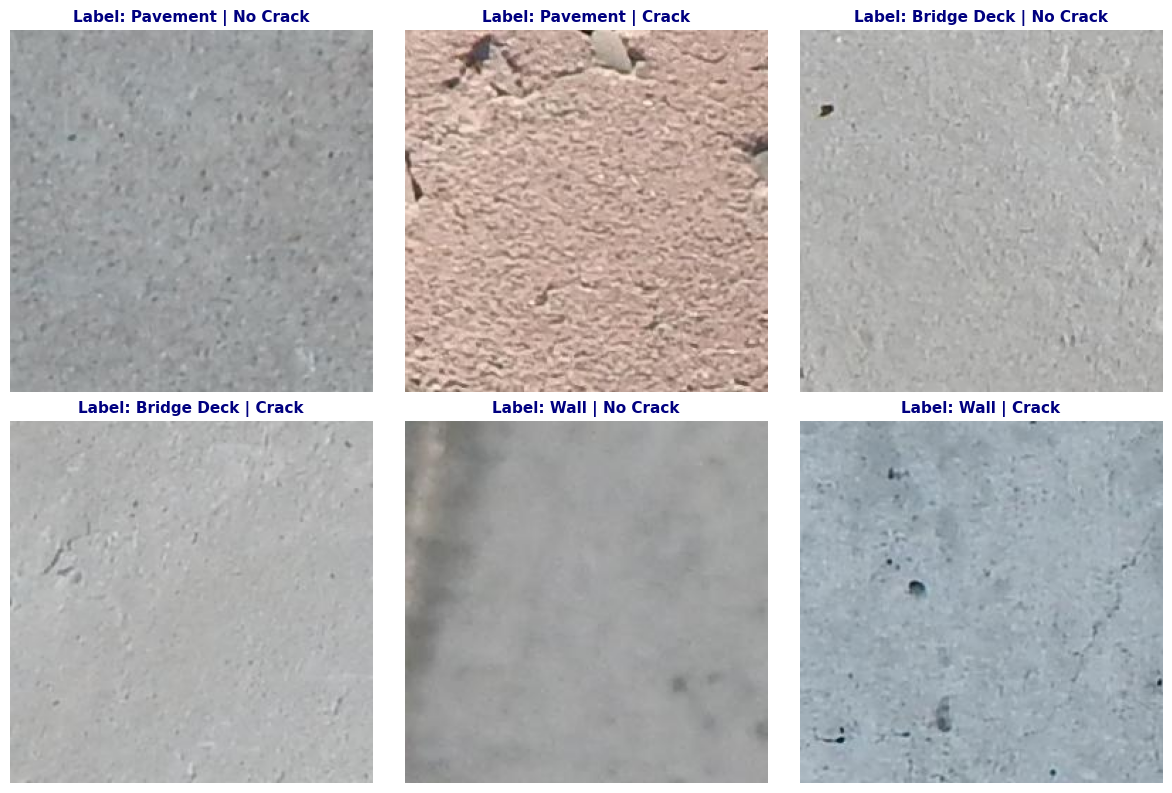


⚙️ Extracting 205-D spatial feature vectors for dataset images...


100%|██████████| 56092/56092 [05:11<00:00, 180.16it/s] 



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Accuracy           : 67.25%
 • Precision          : 0.6763
 • Recall/Sensitivity : 0.6725
 • F1-Score           : 0.6707

---> Random Forest [2-Class (Condition)]
 • Accuracy           : 67.25%
 • Precision          : 0.6739
 • Recall/Sensitivity : 0.6725
 • F1-Score           : 0.6719

---> XGBoost [2-Class (Condition)]
 • Accuracy           : 66.64%
 • Precision          : 0.6667
 • Recall/Sensitivity : 0.6664
 • F1-Score           : 0.6663

---> Decision Tree [2-Class (Condition)]
 • Accuracy           : 59.67%
 • Precision          : 0.5967
 • Recall/Sensitivity : 0.5967
 • F1-Score           : 0.5966


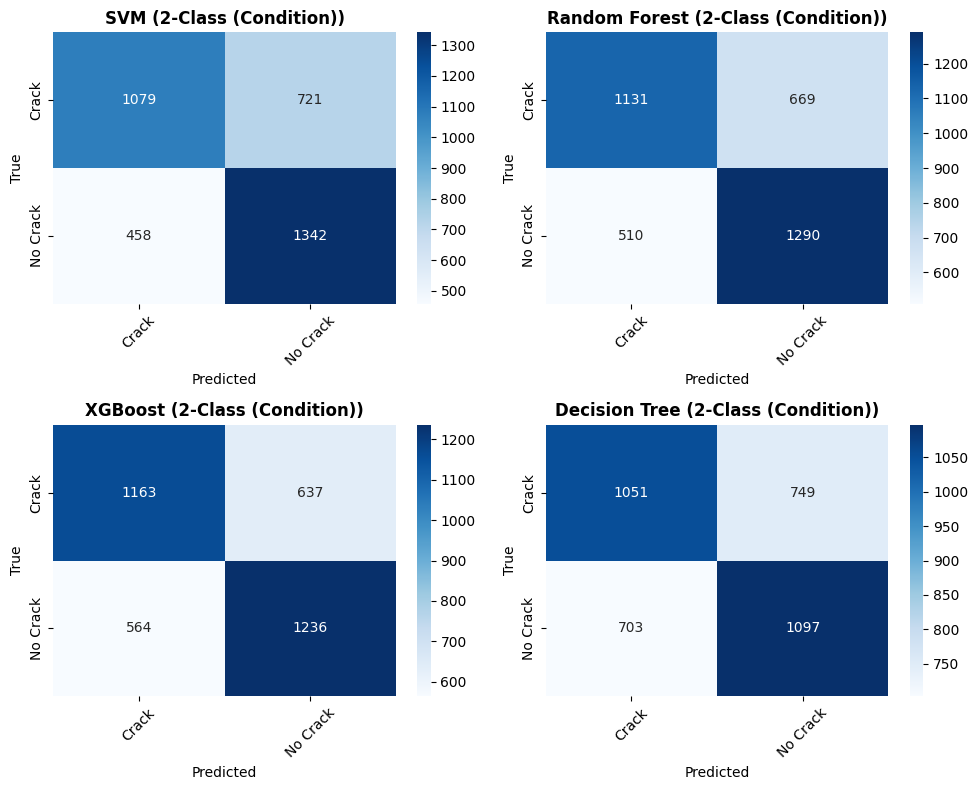


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Accuracy           : 84.42%
 • Precision          : 0.8445
 • Recall/Sensitivity : 0.8442
 • F1-Score           : 0.8443

---> Random Forest [3-Class (Surface Structure)]
 • Accuracy           : 84.83%
 • Precision          : 0.8526
 • Recall/Sensitivity : 0.8483
 • F1-Score           : 0.8493

---> XGBoost [3-Class (Surface Structure)]
 • Accuracy           : 86.28%
 • Precision          : 0.8638
 • Recall/Sensitivity : 0.8628
 • F1-Score           : 0.8631

---> Decision Tree [3-Class (Surface Structure)]
 • Accuracy           : 75.00%
 • Precision          : 0.7493
 • Recall/Sensitivity : 0.7500
 • F1-Score           : 0.7496


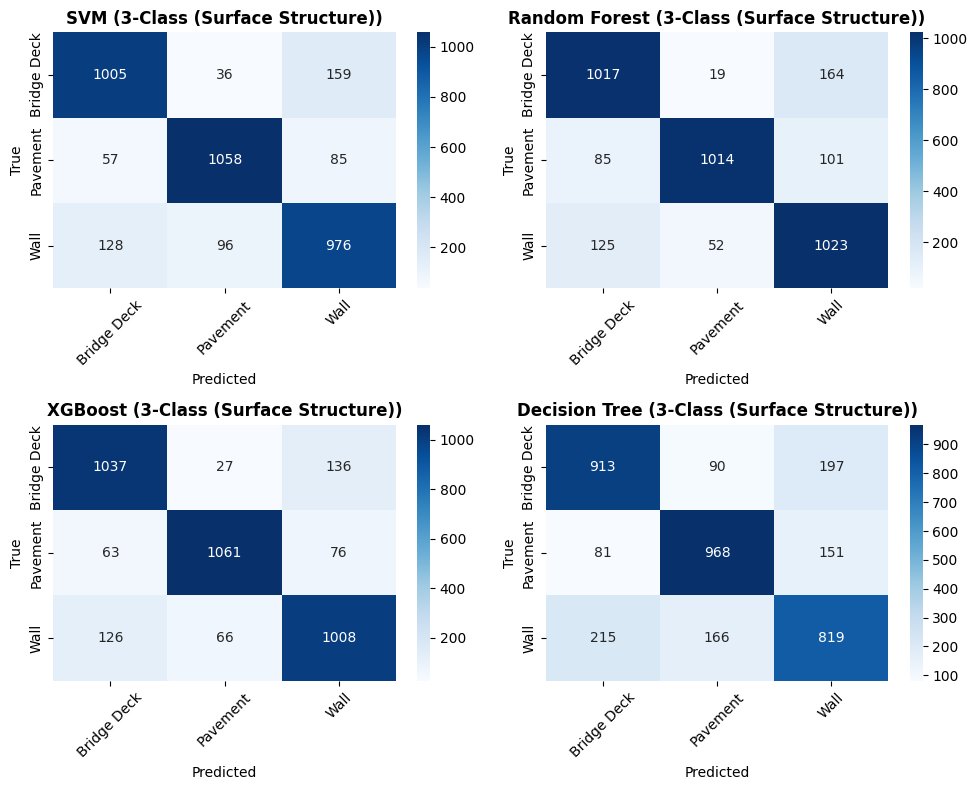


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Accuracy           : 56.58%
 • Precision          : 0.5674
 • Recall/Sensitivity : 0.5658
 • F1-Score           : 0.5659

---> Random Forest [6-Class (Fine-Grained)]
 • Accuracy           : 57.50%
 • Precision          : 0.5783
 • Recall/Sensitivity : 0.5750
 • F1-Score           : 0.5730

---> XGBoost [6-Class (Fine-Grained)]
 • Accuracy           : 59.11%
 • Precision          : 0.5919
 • Recall/Sensitivity : 0.5911
 • F1-Score           : 0.5901

---> Decision Tree [6-Class (Fine-Grained)]
 • Accuracy           : 47.64%
 • Precision          : 0.4743
 • Recall/Sensitivity : 0.4764
 • F1-Score           : 0.4736


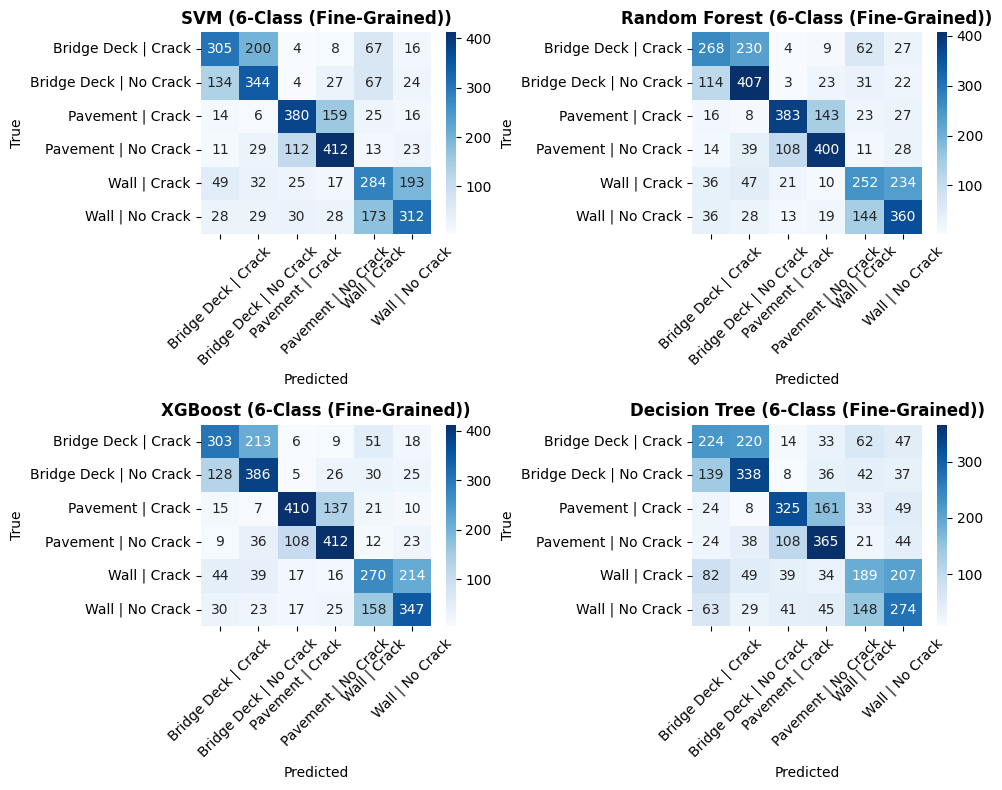


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [4]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30  # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Increased sample size per class for stronger performance

# =====================================================================
# 1. SPATIAL GRID FEATURE EXTRACTION FUNCTION (205-D VECTOR)
# =====================================================================
def extract_cell_features(img_patch, num_angle_bins=36):
    """Extracts 41-D features for an individual image patch."""
    if img_patch.size == 0:
        return np.zeros(41)

    blurred = cv2.GaussianBlur(img_patch, (5, 5), 0)
    edges = cv2.Canny(blurred, threshold1=30, threshold2=70)
    edge_mask = (edges == 255)

    sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

    magnitude = np.sqrt(sobelx**2 + sobely**2)
    mag_values = magnitude[edge_mask] if np.any(edge_mask) else magnitude.ravel()

    # 5 Statistical Features
    mag_mean = float(np.mean(mag_values)) if len(mag_values) > 0 else 0.0
    mag_std = float(np.std(mag_values)) if len(mag_values) > 0 else 0.0
    mag_var = float(np.var(mag_values)) if len(mag_values) > 0 else 0.0
    mag_skew = float(skew(mag_values)) if len(mag_values) > 1 else 0.0
    mag_kurt = float(kurtosis(mag_values)) if len(mag_values) > 1 else 0.0

    stats_vector = [mag_mean, mag_std, mag_var, mag_skew, mag_kurt]

    # 36-Bin Orientation Histogram
    angles_2d = np.arctan2(sobely, sobelx) * 180 / np.pi
    angles_2d = np.mod(angles_2d, 180)  
    edge_angles_1d = angles_2d[edge_mask] if np.any(edge_mask) else angles_2d.ravel()

    angle_hist, _ = np.histogram(edge_angles_1d, bins=num_angle_bins, range=(0, 180), density=True)
    return np.hstack((stats_vector, angle_hist))


def extract_spatial_gradient_features(img_path, grid_size=(2, 2)):
    """
    Extracts global features + 2x2 grid local features.
    Total Dimensions = 41 (Global) + 4 * 41 (Grid Cells) = 205 Dimensions
    """
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None

    # Global Image Features (41-D)
    global_feats = extract_cell_features(img)

    # Spatial Grid Features (4 x 41-D = 164-D)
    h, w = img.shape
    rh, rw = h // grid_size[0], w // grid_size[1]
    
    grid_feats = []
    for r in range(grid_size[0]):
        for c in range(grid_size[1]):
            cell = img[r*rh:(r+1)*rh, c*rw:(c+1)*rw]
            grid_feats.append(extract_cell_features(cell))

    # Combine into single 205-D Feature Vector
    return np.hstack([global_feats] + grid_feats)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

for idx, (label_name, sample_path) in enumerate(class_samples.items()):
    if idx < 6:
        sample_img = cv2.imread(sample_path)
        sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(sample_img)
        axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

# Shuffle dataset paths to get random representative samples
np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 205-D spatial feature vectors for dataset images...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_spatial_gradient_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# =====================================================================
# 5. PIPELINE TRAINER (2-CLASS, 3-CLASS, 6-CLASS)
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    # Models wrapped with Standard Scalers inside Pipelines
    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42)),
        "XGBoost": make_pipeline(StandardScaler(), XGBClassifier(n_estimators=200, learning_rate=0.08, eval_metric='mlogloss', random_state=42)),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        
        acc = accuracy_score(y_test, preds)
        prec = precision_score(y_test, preds, average='weighted', zero_division=0)
        rec = recall_score(y_test, preds, average='weighted', zero_division=0)
        f1 = f1_score(y_test, preds, average='weighted', zero_division=0)
        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "cm": cm
        }

        print(f"\n---> {name} [{task_name}]")
        print(f" • Accuracy           : {acc * 100:.2f}%")
        print(f" • Precision          : {prec:.4f}")
        print(f" • Recall/Sensitivity : {rec:.4f}")
        print(f" • F1-Score           : {f1:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_spatial_gradient_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            detected_surface, detected_condition = pred_label.split(" | ")

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()

345-D spatial HOG feature 

🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


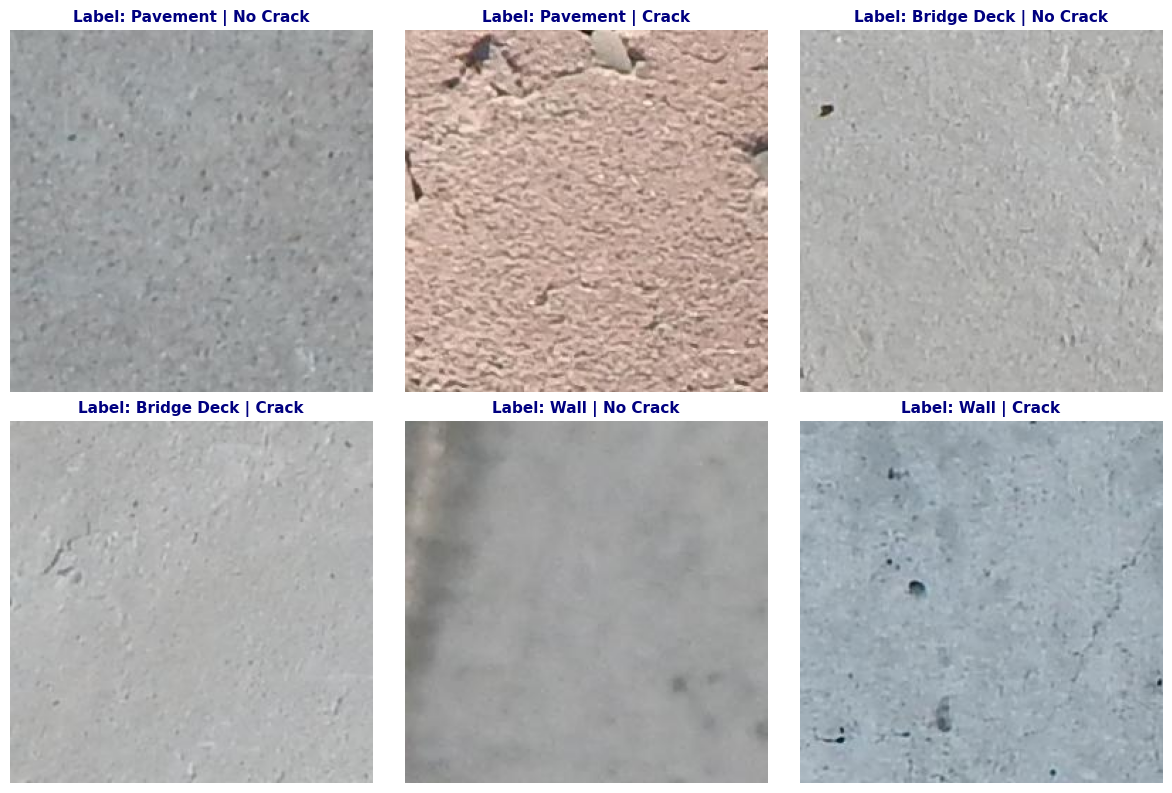


⚙️ Extracting 345-D spatial HOG feature vectors for dataset images...


100%|██████████| 56092/56092 [09:11<00:00, 101.76it/s]



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Accuracy            : 62.47%
 • Precision          : 0.6247
 • Recall/Sensitivity : 0.6247
 • F1-Score            : 0.6247

---> Random Forest [2-Class (Condition)]
 • Accuracy            : 65.56%
 • Precision          : 0.6580
 • Recall/Sensitivity : 0.6556
 • F1-Score            : 0.6542

---> XGBoost [2-Class (Condition)]
 • Accuracy            : 64.72%
 • Precision          : 0.6482
 • Recall/Sensitivity : 0.6472
 • F1-Score            : 0.6466

---> Decision Tree [2-Class (Condition)]
 • Accuracy            : 59.36%
 • Precision          : 0.5992
 • Recall/Sensitivity : 0.5936
 • F1-Score            : 0.5878


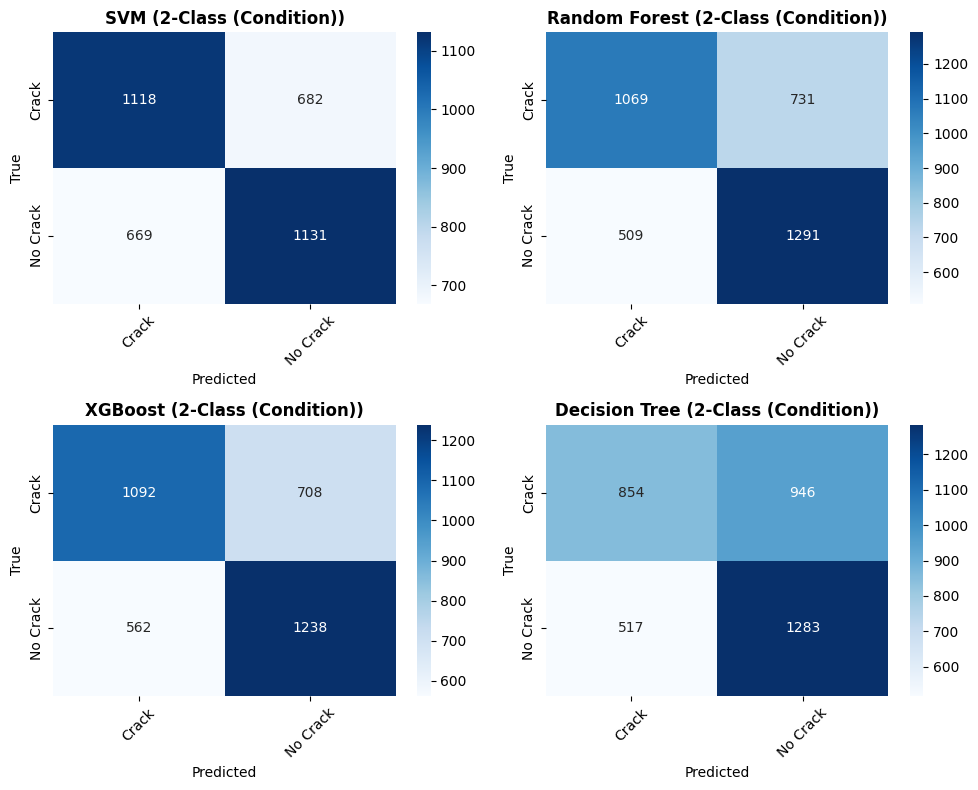


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Accuracy            : 89.17%
 • Precision          : 0.8923
 • Recall/Sensitivity : 0.8917
 • F1-Score            : 0.8919

---> Random Forest [3-Class (Surface Structure)]
 • Accuracy            : 88.58%
 • Precision          : 0.8868
 • Recall/Sensitivity : 0.8858
 • F1-Score            : 0.8861

---> XGBoost [3-Class (Surface Structure)]
 • Accuracy            : 90.00%
 • Precision          : 0.9008
 • Recall/Sensitivity : 0.9000
 • F1-Score            : 0.9002

---> Decision Tree [3-Class (Surface Structure)]
 • Accuracy            : 76.11%
 • Precision          : 0.7618
 • Recall/Sensitivity : 0.7611
 • F1-Score            : 0.7612


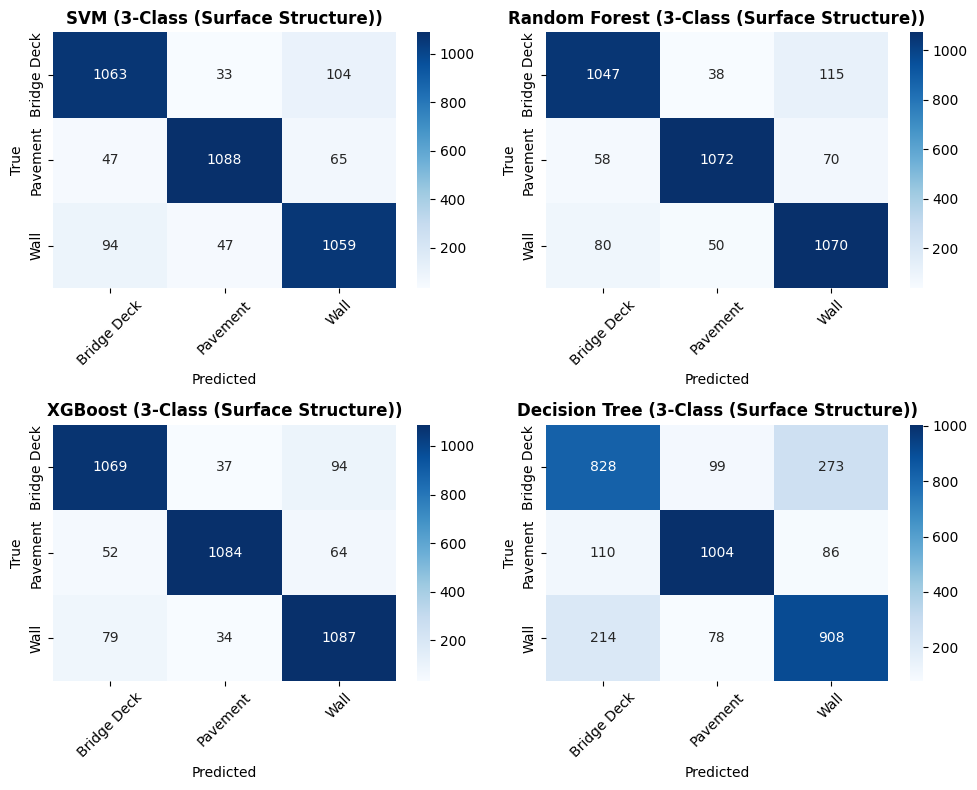


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Accuracy            : 56.39%
 • Precision          : 0.5638
 • Recall/Sensitivity : 0.5639
 • F1-Score            : 0.5636

---> Random Forest [6-Class (Fine-Grained)]
 • Accuracy            : 56.42%
 • Precision          : 0.5670
 • Recall/Sensitivity : 0.5642
 • F1-Score            : 0.5641

---> XGBoost [6-Class (Fine-Grained)]
 • Accuracy            : 59.19%
 • Precision          : 0.5949
 • Recall/Sensitivity : 0.5919
 • F1-Score            : 0.5919

---> Decision Tree [6-Class (Fine-Grained)]
 • Accuracy            : 44.00%
 • Precision          : 0.4391
 • Recall/Sensitivity : 0.4400
 • F1-Score            : 0.4383


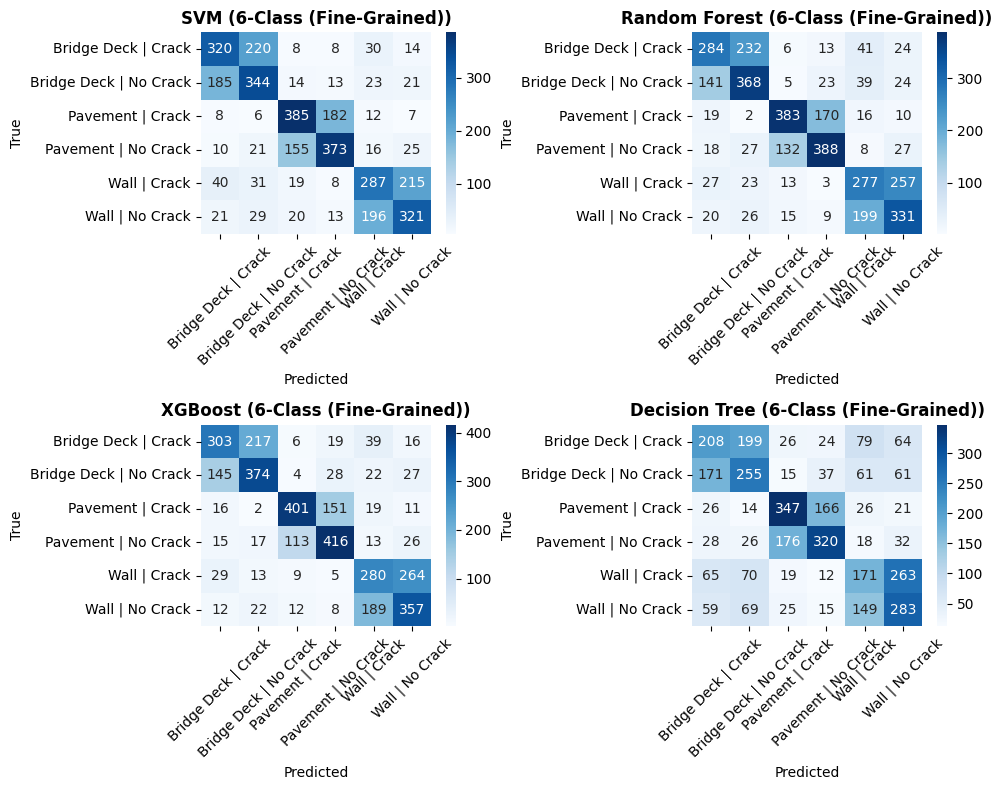


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from skimage.feature import hog
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30  # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Sample size per class for training

# =====================================================================
# 1. HOG + GRADIENT STATS FEATURE EXTRACTION (345-D VECTOR)
# =====================================================================
def extract_cell_features(img_patch):
    """
    Extracts HOG (Histogram of Oriented Gradients) + Gradient Magnitude Stats
    for an individual image patch.
    """
    if img_patch is None or img_patch.size == 0:
        return np.zeros(69)

    # Pre-processing: Smooth surface noise while preserving crack boundaries
    gray_prep = cv2.bilateralFilter(img_patch, d=7, sigmaColor=50, sigmaSpace=50)

    # Resize patch to fixed size for uniform HOG vector dimensions
    patch_resized = cv2.resize(gray_prep, (128, 128))

    # --- 1. HOG Feature Vector Extraction ---
    hog_feats = hog(
        patch_resized,
        orientations=8,
        pixels_per_cell=(16, 16),
        cells_per_block=(1, 1),
        visualize=False,
        channel_axis=None
    )  # Produces exactly 64 HOG features (8x8 cells * 8 orientations)

    # --- 2. Gradient Magnitude Statistics ---
    sobelx = cv2.Sobel(patch_resized, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(patch_resized, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = np.sqrt(sobelx**2 + sobely**2).ravel()

    mag_mean = float(np.mean(magnitude)) if len(magnitude) > 0 else 0.0
    mag_std = float(np.std(magnitude)) if len(magnitude) > 0 else 0.0
    mag_var = float(np.var(magnitude)) if len(magnitude) > 0 else 0.0
    mag_skew = float(skew(magnitude)) if len(magnitude) > 1 else 0.0
    mag_kurt = float(kurtosis(magnitude)) if len(magnitude) > 1 else 0.0

    stats_vector = np.array([mag_mean, mag_std, mag_var, mag_skew, mag_kurt])

    # Combine into 69-D Feature Vector per patch
    return np.hstack((hog_feats, stats_vector))


def extract_spatial_gradient_features(img_path, grid_size=(2, 2)):
    """
    Extracts global HOG features + 2x2 grid local HOG features.
    Total Dimensions = 69 (Global) + 4 * 69 (Grid Cells) = 345 Dimensions
    """
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None

    # Global Image Features (69-D)
    global_feats = extract_cell_features(img)

    # Spatial Grid Features (4 x 69-D = 276-D)
    h, w = img.shape
    rh, rw = h // grid_size[0], w // grid_size[1]
    
    grid_feats = []
    for r in range(grid_size[0]):
        for c in range(grid_size[1]):
            cell = img[r*rh:(r+1)*rh, c*rw:(c+1)*rw]
            grid_feats.append(extract_cell_features(cell))

    # Combine into single 345-D Feature Vector
    return np.hstack([global_feats] + grid_feats)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

for idx, (label_name, sample_path) in enumerate(class_samples.items()):
    if idx < 6:
        sample_img = cv2.imread(sample_path)
        sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(sample_img)
        axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

# Shuffle dataset paths to get random representative samples
np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 345-D spatial HOG feature vectors for dataset images...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_spatial_gradient_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# =====================================================================
# 5. PIPELINE TRAINER (2-CLASS, 3-CLASS, 6-CLASS)
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    # Models wrapped with Standard Scalers inside Pipelines
    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)),
        "XGBoost": make_pipeline(StandardScaler(), XGBClassifier(n_estimators=200, learning_rate=0.08, eval_metric='mlogloss', random_state=42, n_jobs=-1)),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        
        acc = accuracy_score(y_test, preds)
        prec = precision_score(y_test, preds, average='weighted', zero_division=0)
        rec = recall_score(y_test, preds, average='weighted', zero_division=0)
        f1 = f1_score(y_test, preds, average='weighted', zero_division=0)
        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "cm": cm
        }

        print(f"\n---> {name} [{task_name}]")
        print(f" • Accuracy            : {acc * 100:.2f}%")
        print(f" • Precision          : {prec:.4f}")
        print(f" • Recall/Sensitivity : {rec:.4f}")
        print(f" • F1-Score            : {f1:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_spatial_gradient_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            detected_surface, detected_condition = pred_label.split(" | ")

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()

320-D spatial HOG feature vectors 

🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


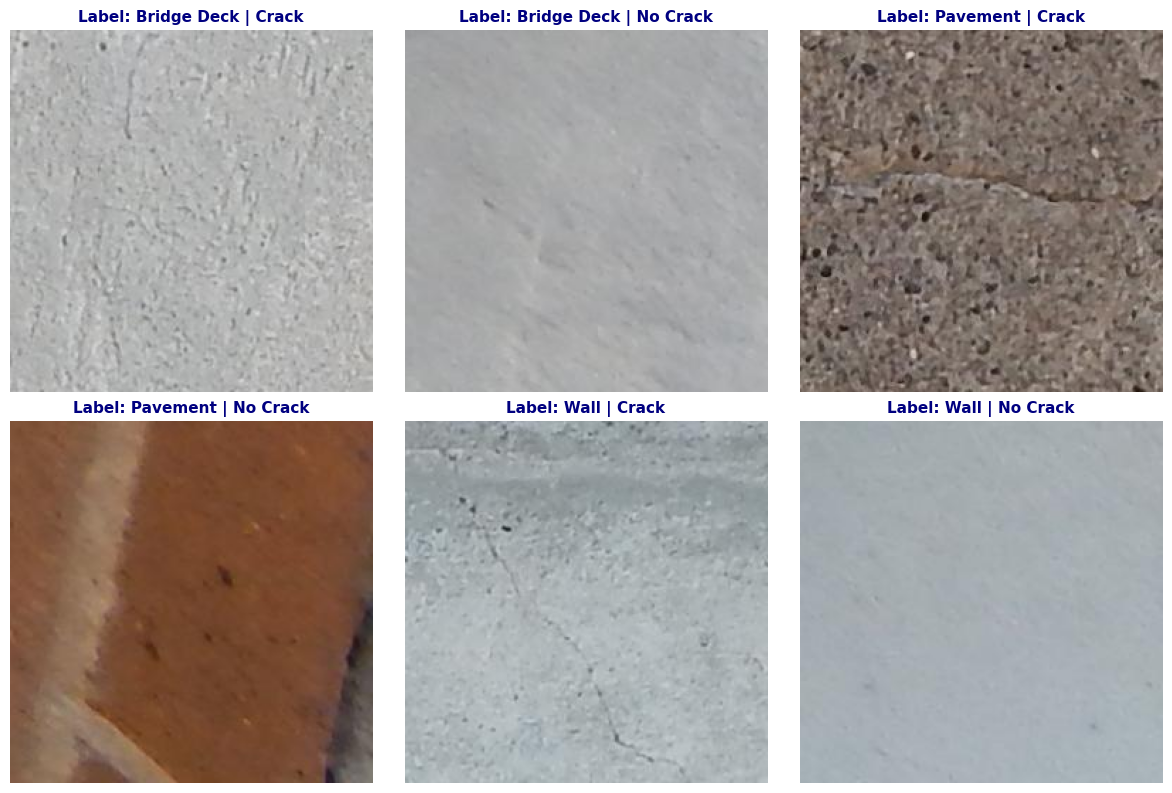


⚙️ Extracting 320-D spatial HOG feature vectors for dataset images...


100%|██████████| 56092/56092 [14:37<00:00, 63.92it/s]  



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Accuracy            : 60.22%
 • Precision          : 0.6023
 • Recall             : 0.6022
 • Sensitivity        : 0.6022
 • F1-Score            : 0.6022

---> Random Forest [2-Class (Condition)]
 • Accuracy            : 61.44%
 • Precision          : 0.6217
 • Recall             : 0.6144
 • Sensitivity        : 0.6144
 • F1-Score            : 0.6086

---> XGBoost [2-Class (Condition)]
 • Accuracy            : 60.83%
 • Precision          : 0.6092
 • Recall             : 0.6083
 • Sensitivity        : 0.6083
 • F1-Score            : 0.6075

---> Decision Tree [2-Class (Condition)]
 • Accuracy            : 52.08%
 • Precision          : 0.

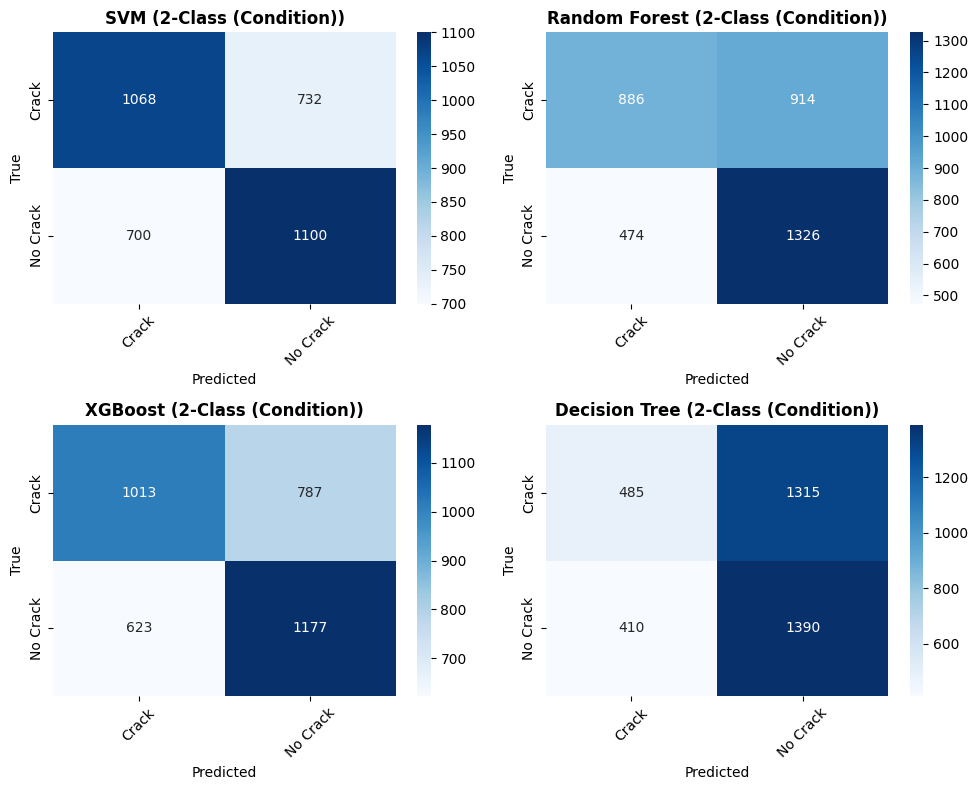


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Accuracy            : 85.39%
 • Precision          : 0.8546
 • Recall             : 0.8539
 • Sensitivity        : 0.8539
 • F1-Score            : 0.8542

---> Random Forest [3-Class (Surface Structure)]
 • Accuracy            : 82.86%
 • Precision          : 0.8283
 • Recall             : 0.8286
 • Sensitivity        : 0.8286
 • F1-Score            : 0.8284

---> XGBoost [3-Class (Surface Structure)]
 • Accuracy            : 85.53%
 • Precision          : 0.8556
 • Recall             : 0.8553
 • Sensitivity        : 0.8553
 • F1-Score            : 0.8554

---> Decision Tree [3-Class (Surface Structure)]
 • Accuracy            : 66.39%
 • Precision          : 0.6646
 • Recall             : 0.6639
 • Sensitivity        : 0.6639
 • F1-Score            : 0.6641


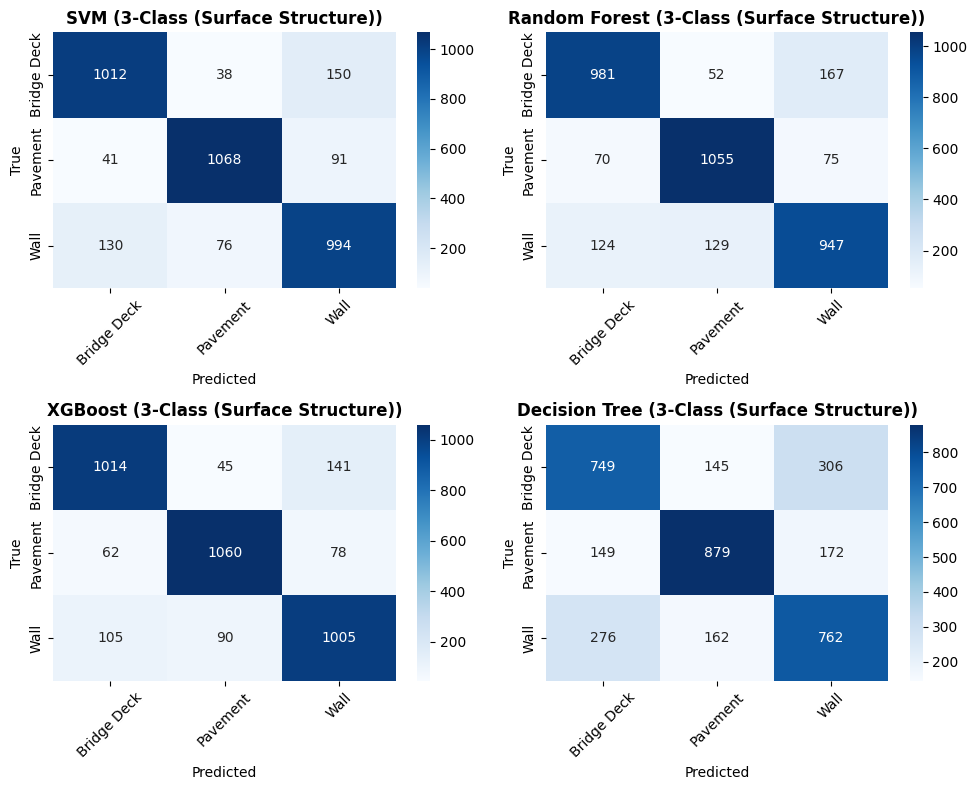


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Accuracy            : 53.81%
 • Precision          : 0.5376
 • Recall             : 0.5381
 • Sensitivity        : 0.5381
 • F1-Score            : 0.5376

---> Random Forest [6-Class (Fine-Grained)]
 • Accuracy            : 47.14%
 • Precision          : 0.4726
 • Recall             : 0.4714
 • Sensitivity        : 0.4714
 • F1-Score            : 0.4711

---> XGBoost [6-Class (Fine-Grained)]
 • Accuracy            : 49.47%
 • Precision          : 0.4957
 • Recall             : 0.4947
 • Sensitivity        : 0.4947
 • F1-Score            : 0.4939

---> Decision Tree [6-Class (Fine-Grained)]
 • Accuracy            : 34.03%
 • Precision          : 0.3417
 • Recall             : 0.3403
 • Sensitivity        : 0.3403
 • F1-Score            : 0.3396


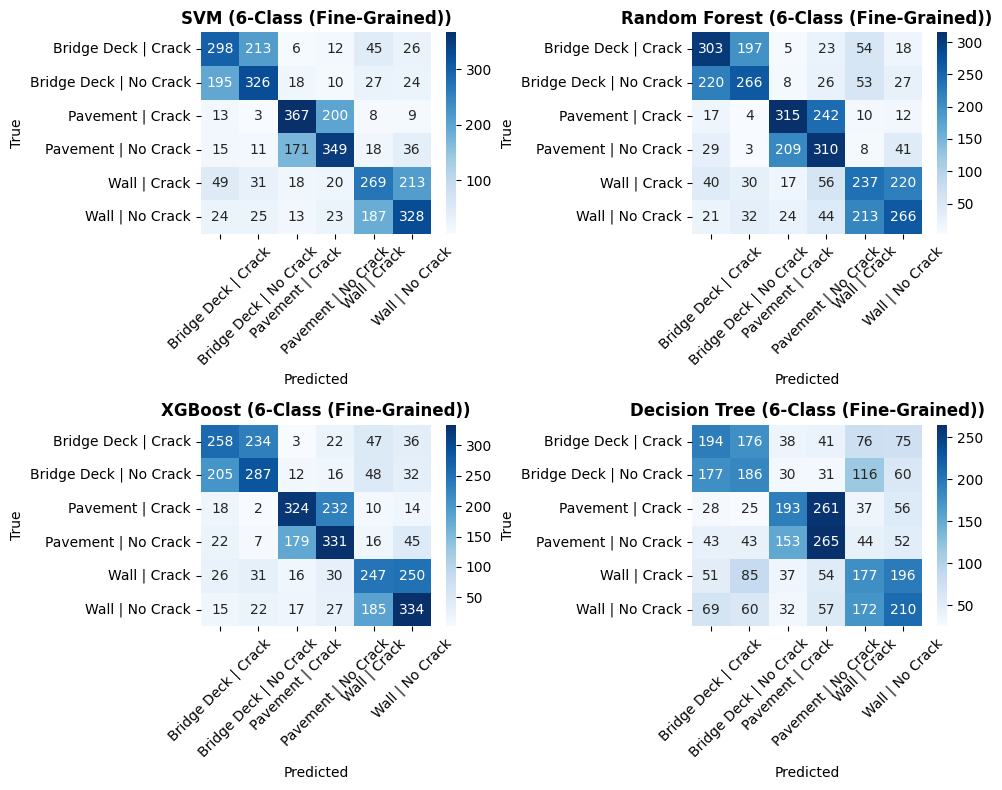


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, 
    precision_recall_fscore_support, 
    confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30  # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Sample size per class for training

# =====================================================================
# 1. HOG ONLY FEATURE EXTRACTION (320-D VECTOR TOTAL)
# =====================================================================
def extract_cell_features(img_patch):
    """
    Extracts strictly HOG (Histogram of Oriented Gradients) features 
    for an individual image patch.
    """
    if img_patch is None or img_patch.size == 0:
        return np.zeros(64)

    # Pre-processing: Smooth surface noise while preserving crack boundaries
    gray_prep = cv2.bilateralFilter(img_patch, d=7, sigmaColor=50, sigmaSpace=50)

    # Resize patch to fixed size for uniform HOG vector dimensions
    patch_resized = cv2.resize(gray_prep, (128, 128))

    # --- HOG Feature Vector Extraction Only ---
    hog_feats = hog(
        patch_resized,
        orientations=8,
        pixels_per_cell=(16, 16),
        cells_per_block=(1, 1),
        visualize=False,
        channel_axis=None
    )  # Produces exactly 64 HOG features (8x8 cells * 8 orientations)

    return hog_feats


def extract_spatial_gradient_features(img_path, grid_size=(2, 2)):
    """
    Extracts global HOG features + 2x2 grid local HOG features.
    Total Dimensions = 64 (Global) + 4 * 64 (Grid Cells) = 320 Dimensions
    """
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None

    # Global Image Features (64-D)
    global_feats = extract_cell_features(img)

    # Spatial Grid Features (4 x 64-D = 256-D)
    h, w = img.shape
    rh, rw = h // grid_size[0], w // grid_size[1]
    
    grid_feats = []
    for r in range(grid_size[0]):
        for c in range(grid_size[1]):
            cell = img[r*rh:(r+1)*rh, c*rw:(c+1)*rw]
            grid_feats.append(extract_cell_features(cell))

    # Combine into single 320-D Feature Vector
    return np.hstack([global_feats] + grid_feats)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

for idx, (label_name, sample_path) in enumerate(class_samples.items()):
    if idx < 6:
        sample_img = cv2.imread(sample_path)
        sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(sample_img)
        axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

# Shuffle dataset paths to get random representative samples
np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 320-D spatial HOG feature vectors for dataset images...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_spatial_gradient_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# =====================================================================
# 5. PIPELINE TRAINER USING INBUILT SKLEARN STATISTICAL METRICS
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    # Models wrapped with Standard Scalers inside Pipelines
    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)),
        "XGBoost": make_pipeline(StandardScaler(), XGBClassifier(n_estimators=200, learning_rate=0.08, eval_metric='mlogloss', random_state=42, n_jobs=-1)),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        
        # Inbuilt Accuracy
        acc = accuracy_score(y_test, preds)

        # Inbuilt Precision, Recall (Sensitivity), and F1-Score
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_test, preds, average='weighted', zero_division=0
        )
        
        sensitivity = rec  # Sensitivity is equivalent to Recall

        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, 
            "precision": prec, 
            "recall": rec, 
            "sensitivity": sensitivity, 
            "f1": f1, 
            "cm": cm
        }

        print(f"\n---> {name} [{task_name}]")
        print(f" • Accuracy            : {acc * 100:.2f}%")
        print(f" • Precision          : {prec:.4f}")
        print(f" • Recall             : {rec:.4f}")
        print(f" • Sensitivity        : {sensitivity:.4f}")
        print(f" • F1-Score            : {f1:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_spatial_gradient_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            detected_surface, detected_condition = pred_label.split(" | ")

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()

applying shi-tomasi for feature vector (with image Grid Patch)

🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


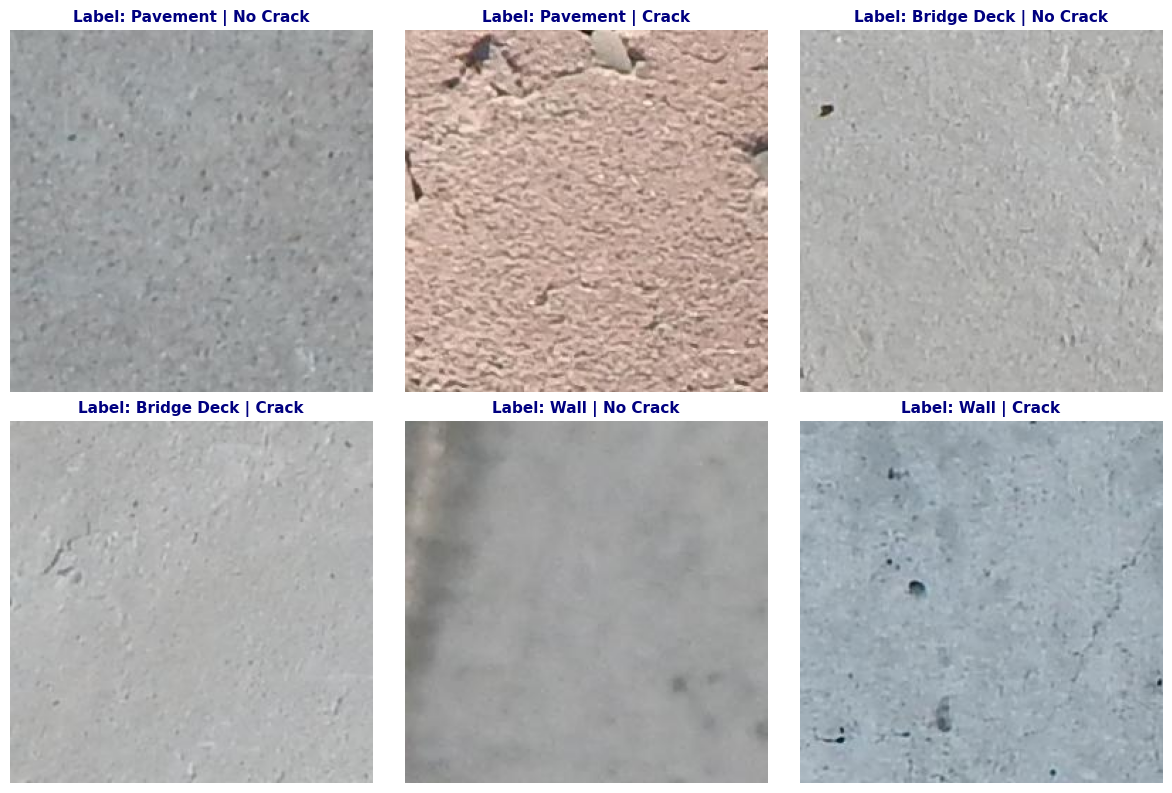


⚙️ Extracting 300-D Shi-Tomasi feature vectors for dataset images...


100%|██████████| 56092/56092 [02:35<00:00, 360.98it/s] 



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Overall Accuracy   : 57.56%
 • Macro Precision    : 0.5756
 • Macro Sensitivity  : 0.5756  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5755

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.5761 | Sensitivity/Recall: 0.5717 | F1: 0.5739
   - No Crack             | Precision: 0.5750 | Sensitivity/Recall: 0.5794 | F1: 0.5772

---> Random Forest [2-Class (Condition)]
 • Overall Accuracy   : 62.36%
 • Macro Precision    : 0.6242
 • Macro Sensitivity  : 0.6236  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6232

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6324 |

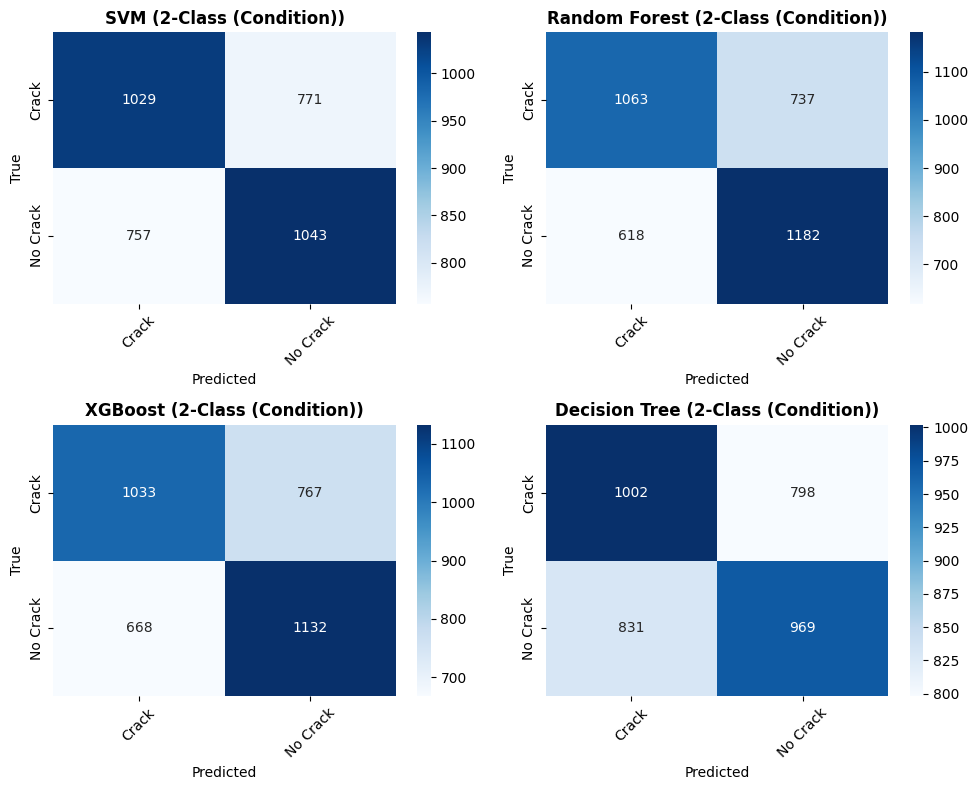


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Overall Accuracy   : 71.78%
 • Macro Precision    : 0.7330
 • Macro Sensitivity  : 0.7178  (Sensitivity = Recall)
 • Macro F1-Score     : 0.7219

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5917 | Sensitivity/Recall: 0.7150 | F1: 0.6475
   - Pavement             | Precision: 0.9099 | Sensitivity/Recall: 0.8083 | F1: 0.8561
   - Wall                 | Precision: 0.6974 | Sensitivity/Recall: 0.6300 | F1: 0.6620

---> Random Forest [3-Class (Surface Structure)]
 • Overall Accuracy   : 80.11%
 • Macro Precision    : 0.8054
 • Macro Sensitivity  : 0.8011  (Sensitivity = Recall)
 • Macro F1-Score     : 0.8026

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.7151 | Sensitivity/Recall: 0.7717 | F1: 0.7423
   - Pavement             | Precision: 0.9033 | Sensitivity/Recall: 0.8483 | F1: 0.8749
   - Wall  

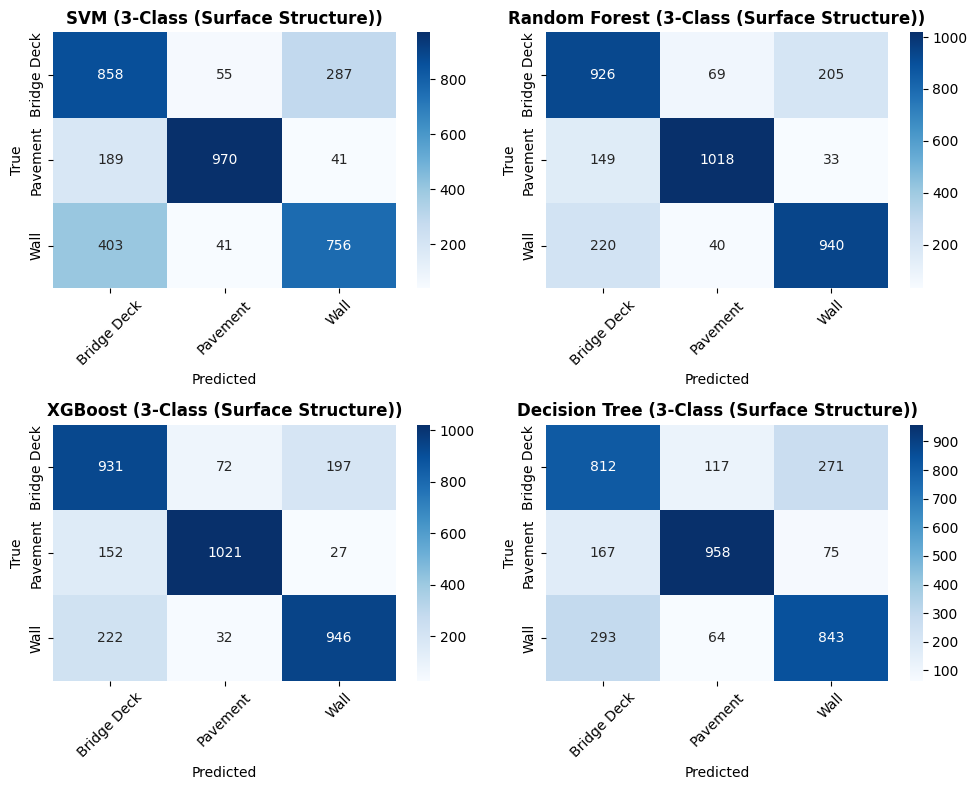


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Overall Accuracy   : 42.08%
 • Macro Precision    : 0.4302
 • Macro Sensitivity  : 0.4208  (Sensitivity = Recall)
 • Macro F1-Score     : 0.4209

   --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.3377 | Sensitivity/Recall: 0.3850 | F1: 0.3598
   - Bridge Deck | No Crack | Precision: 0.3636 | Sensitivity/Recall: 0.5267 | F1: 0.4302
   - Pavement | Crack     | Precision: 0.5709 | Sensitivity/Recall: 0.5300 | F1: 0.5497
   - Pavement | No Crack  | Precision: 0.5394 | Sensitivity/Recall: 0.4450 | F1: 0.4877
   - Wall | Crack         | Precision: 0.4108 | Sensitivity/Recall: 0.3417 | F1: 0.3731
   - Wall | No Crack      | Precision: 0.3589 | Sensitivity/Recall: 0.2967 | F1: 0.3248

---> Random Forest [6-Class (Fine-Grained)]
 • Overall Accuracy   : 49.25%
 • Macro Precision    : 0.4969
 • Macro Sensitivity  : 0.4925  (Sensitivity = Recall)
 • Macro F1

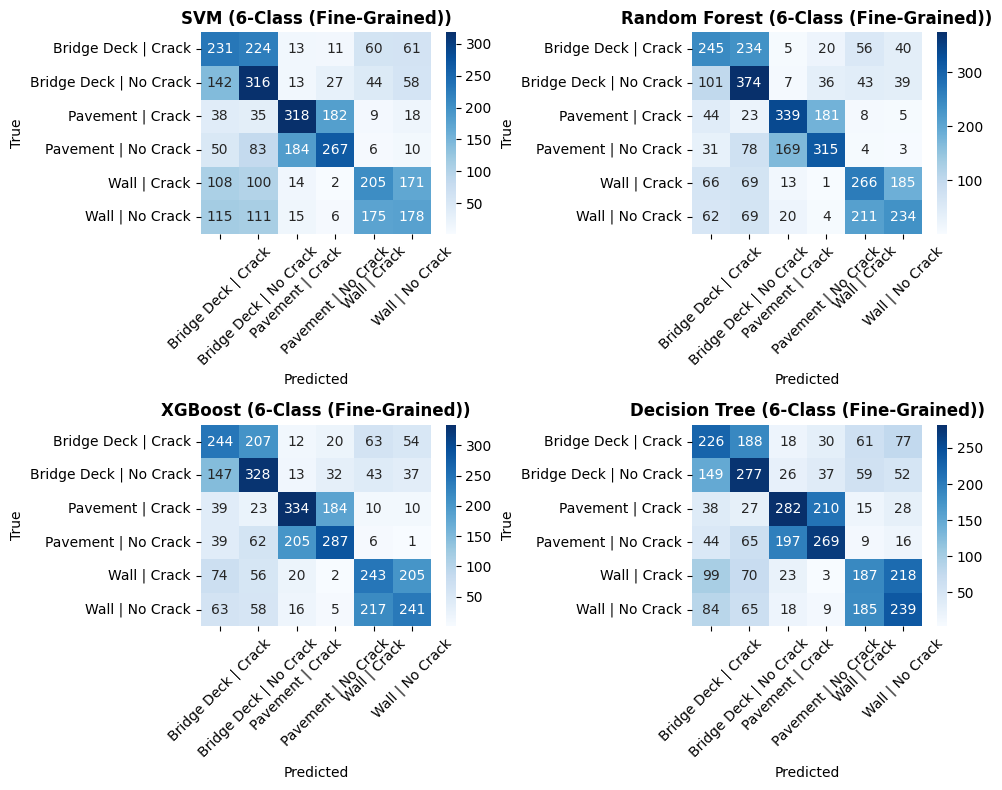


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [3]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30  # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Sample size per class for training

# =====================================================================
# 1. SHI-TOMASI TOP-20 CORNER FEATURE EXTRACTION
# =====================================================================
def extract_cell_features(img_patch, max_corners=20):
    """
    Extracts top-20 Shi-Tomasi corners and converts them into a 
    fixed 60-dimensional vector: [x1, y1, score1, ..., x20, y20, score20]
    """
    if img_patch is None or img_patch.size == 0:
        return np.zeros(max_corners * 3, dtype=np.float32)

    # Pre-processing: Smooth surface noise while preserving crack boundaries
    gray_prep = cv2.bilateralFilter(img_patch, d=7, sigmaColor=50, sigmaSpace=50)

    # Calculate Shi-Tomasi Eigenvalue response map (Min Eigenvalue method)
    corner_map = cv2.cornerMinEigenVal(gray_prep, blockSize=3, ksize=3)
    
    # Detect top corners sorted by Shi-Tomasi quality score
    corners = cv2.goodFeaturesToTrack(
        gray_prep, 
        maxCorners=max_corners, 
        qualityLevel=0.01, 
        minDistance=10
    )
    
    vector = []
    if corners is not None:
        corners = np.int32(corners)
        for pt in corners:
            x, y = pt.ravel()
            score = float(corner_map[y, x]) # Extract corner response score
            vector.extend([x, y, score])
            
    # Force exact target vector length = 60 (20 corners * 3 features)
    target_len = max_corners * 3
    if len(vector) < target_len:
        vector.extend([0.0] * (target_len - len(vector)))  # Zero-padding
    else:
        vector = vector[:target_len]                       # Truncate to top 20
        
    return np.array(vector, dtype=np.float32)


def extract_spatial_gradient_features(img_path, grid_size=(2, 2)):
    """
    Extracts global Shi-Tomasi features + 2x2 grid local Shi-Tomasi features.
    Total Dimensions = 60 (Global) + 4 * 60 (Grid Cells) = 300 Dimensions
    """
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None

    # Global Image Features (60-D)
    global_feats = extract_cell_features(img)

    # Spatial Grid Features (4 x 60-D = 240-D)
    h, w = img.shape
    rh, rw = h // grid_size[0], w // grid_size[1]
    
    grid_feats = []
    for r in range(grid_size[0]):
        for c in range(grid_size[1]):
            cell = img[r*rh:(r+1)*rh, c*rw:(c+1)*rw]
            grid_feats.append(extract_cell_features(cell))

    # Combine into single 300-D Feature Vector
    return np.hstack([global_feats] + grid_feats)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

for idx, (label_name, sample_path) in enumerate(class_samples.items()):
    if idx < 6:
        sample_img = cv2.imread(sample_path)
        sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(sample_img)
        axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

# Shuffle dataset paths to get random representative samples
np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 300-D Shi-Tomasi feature vectors for dataset images...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_spatial_gradient_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X, dtype=np.float32)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# =====================================================================
# 5. PIPELINE TRAINER WITH PER-CLASS BREAKDOWN & MACRO METRICS
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    # Configure XGBoost GPU Classifier
    xgb_clf = XGBClassifier(
        n_estimators=200, 
        learning_rate=0.08, 
        eval_metric='mlogloss', 
        random_state=42, 
        tree_method='hist',
        device='cuda'
    )

    # Models wrapped with Standard Scalers inside Pipelines
    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)),
        "XGBoost": make_pipeline(StandardScaler(), xgb_clf),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        # Fallback to CPU execution if GPU device isn't configured in environment
        try:
            model.fit(X_train, y_train)
        except Exception:
            if name == "XGBoost":
                model.named_steps['xgbclassifier'].set_params(device='cpu')
                model.fit(X_train, y_train)

        preds = model.predict(X_test)
        
        acc = accuracy_score(y_test, preds)
        
        # Macro averaging across all classes
        macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
            y_test, preds, average='macro', zero_division=0
        )
        macro_sens = macro_r  # Sensitivity = Recall

        # Per-class metrics
        per_p, per_r, per_f1, _ = precision_recall_fscore_support(
            y_test, preds, average=None, zero_division=0
        )
        
        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, "precision": macro_p, "recall": macro_r, 
            "sensitivity": macro_sens, "f1": macro_f1, "cm": cm
        }

        # Print formatted output matching target format
        print(f"\n---> {name} [{task_name}]")
        print(f" • Overall Accuracy   : {acc * 100:.2f}%")
        print(f" • Macro Precision    : {macro_p:.4f}")
        print(f" • Macro Sensitivity  : {macro_sens:.4f}  (Sensitivity = Recall)")
        print(f" • Macro F1-Score     : {macro_f1:.4f}\n")
        print("   --- Per-Class Performance Breakdown ---")
        for cls_idx, cls_name in enumerate(le.classes_):
            p_val = per_p[cls_idx]
            r_val = per_r[cls_idx]
            f_val = per_f1[cls_idx]
            print(f"   - {cls_name:<20} | Precision: {p_val:.4f} | Sensitivity/Recall: {r_val:.4f} | F1: {f_val:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_spatial_gradient_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            detected_surface, detected_condition = pred_label.split(" | ")

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()

applying MSER for feature vector with image grid path

🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


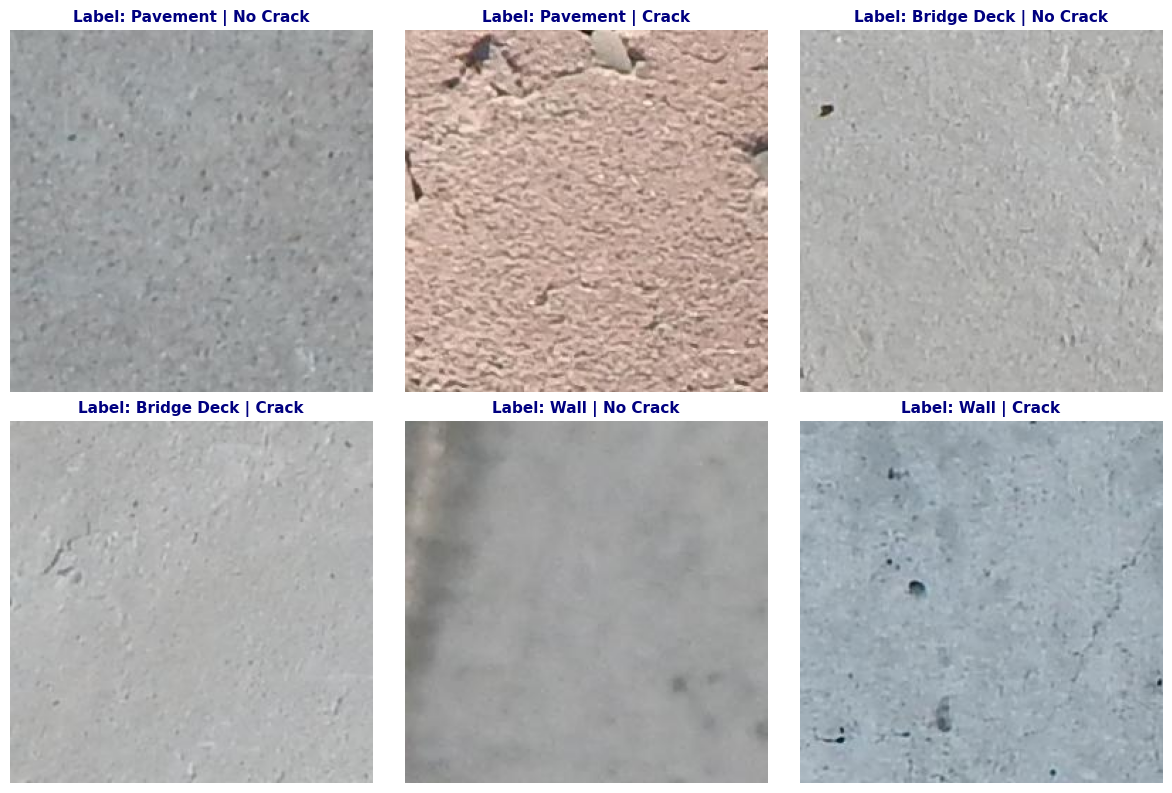


⚙️ Extracting 300-D MSER feature vectors for dataset images...


100%|██████████| 56092/56092 [03:43<00:00, 250.59it/s] 



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Overall Accuracy   : 62.53%
 • Macro Precision    : 0.6356
 • Macro Sensitivity  : 0.6253  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6180

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6731 | Sensitivity/Recall: 0.4872 | F1: 0.5653
   - No Crack             | Precision: 0.5982 | Sensitivity/Recall: 0.7633 | F1: 0.6707

---> Random Forest [2-Class (Condition)]
 • Overall Accuracy   : 64.39%
 • Macro Precision    : 0.6485
 • Macro Sensitivity  : 0.6439  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6411

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6745 |

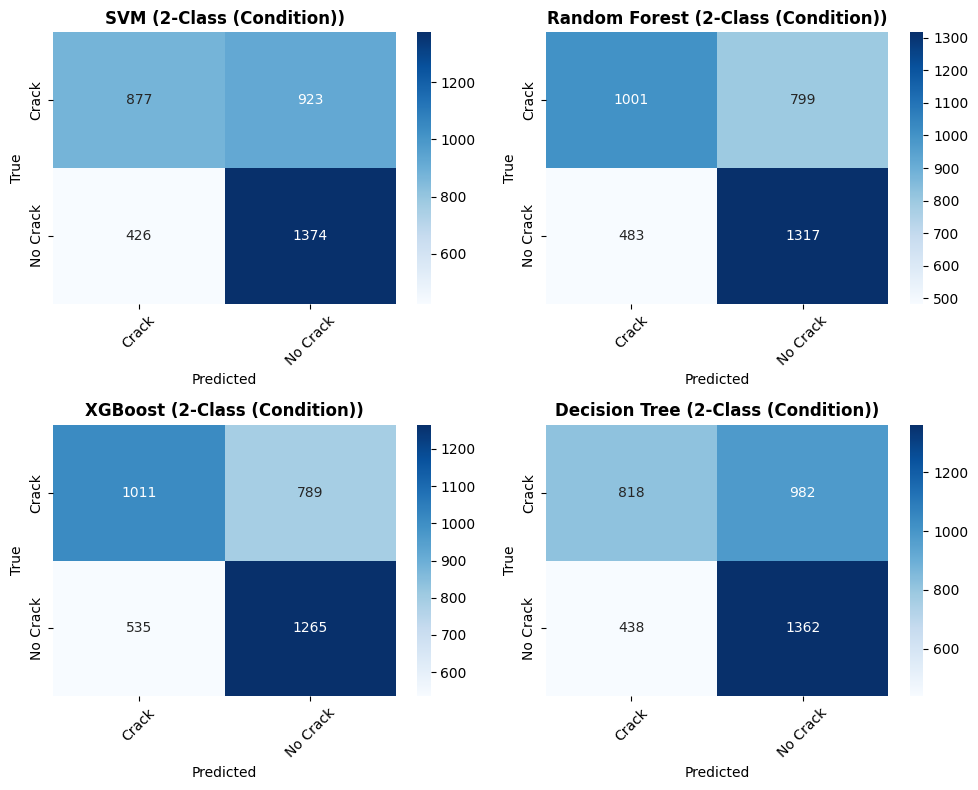


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Overall Accuracy   : 64.50%
 • Macro Precision    : 0.6453
 • Macro Sensitivity  : 0.6450  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6430

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5799 | Sensitivity/Recall: 0.6717 | F1: 0.6224
   - Pavement             | Precision: 0.7919 | Sensitivity/Recall: 0.7800 | F1: 0.7859
   - Wall                 | Precision: 0.5642 | Sensitivity/Recall: 0.4833 | F1: 0.5206

---> Random Forest [3-Class (Surface Structure)]
 • Overall Accuracy   : 68.56%
 • Macro Precision    : 0.6909
 • Macro Sensitivity  : 0.6856  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6870

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.6239 | Sensitivity/Recall: 0.6967 | F1: 0.6583
   - Pavement             | Precision: 0.8336 | Sensitivity/Recall: 0.7683 | F1: 0.7997
   - Wall  

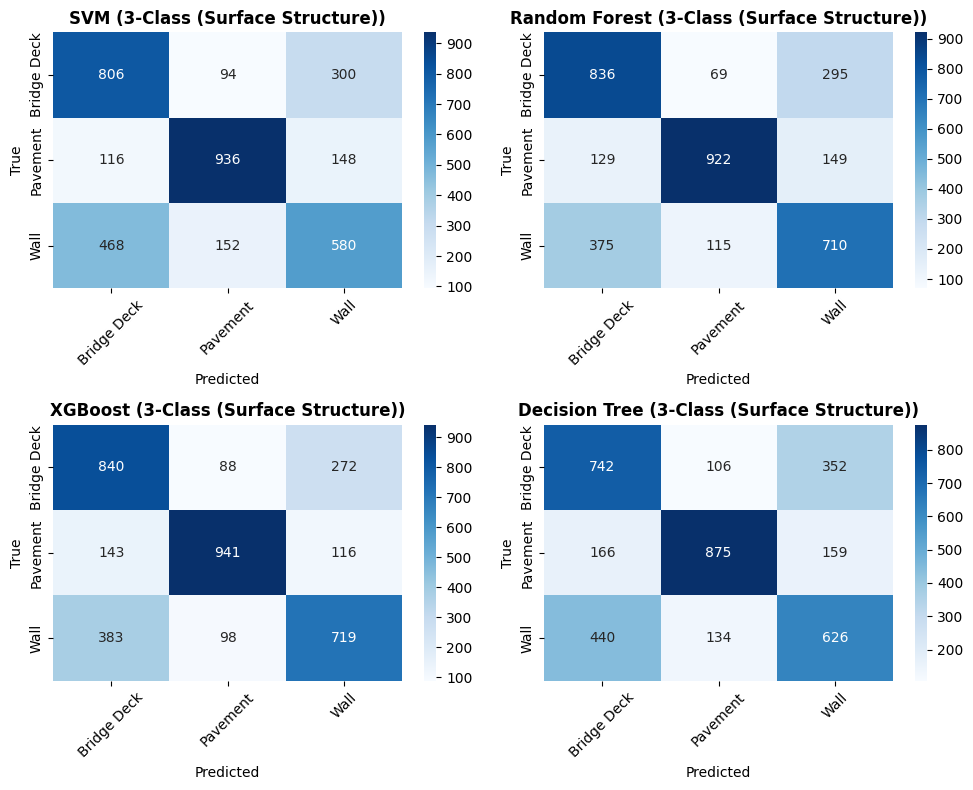


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Overall Accuracy   : 41.72%
 • Macro Precision    : 0.4154
 • Macro Sensitivity  : 0.4172  (Sensitivity = Recall)
 • Macro F1-Score     : 0.4010

   --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.4177 | Sensitivity/Recall: 0.2750 | F1: 0.3317
   - Bridge Deck | No Crack | Precision: 0.3690 | Sensitivity/Recall: 0.6783 | F1: 0.4780
   - Pavement | Crack     | Precision: 0.5647 | Sensitivity/Recall: 0.6183 | F1: 0.5903
   - Pavement | No Crack  | Precision: 0.5094 | Sensitivity/Recall: 0.4500 | F1: 0.4779
   - Wall | Crack         | Precision: 0.3162 | Sensitivity/Recall: 0.1533 | F1: 0.2065
   - Wall | No Crack      | Precision: 0.3157 | Sensitivity/Recall: 0.3283 | F1: 0.3219

---> Random Forest [6-Class (Fine-Grained)]
 • Overall Accuracy   : 45.28%
 • Macro Precision    : 0.4572
 • Macro Sensitivity  : 0.4528  (Sensitivity = Recall)
 • Macro F1

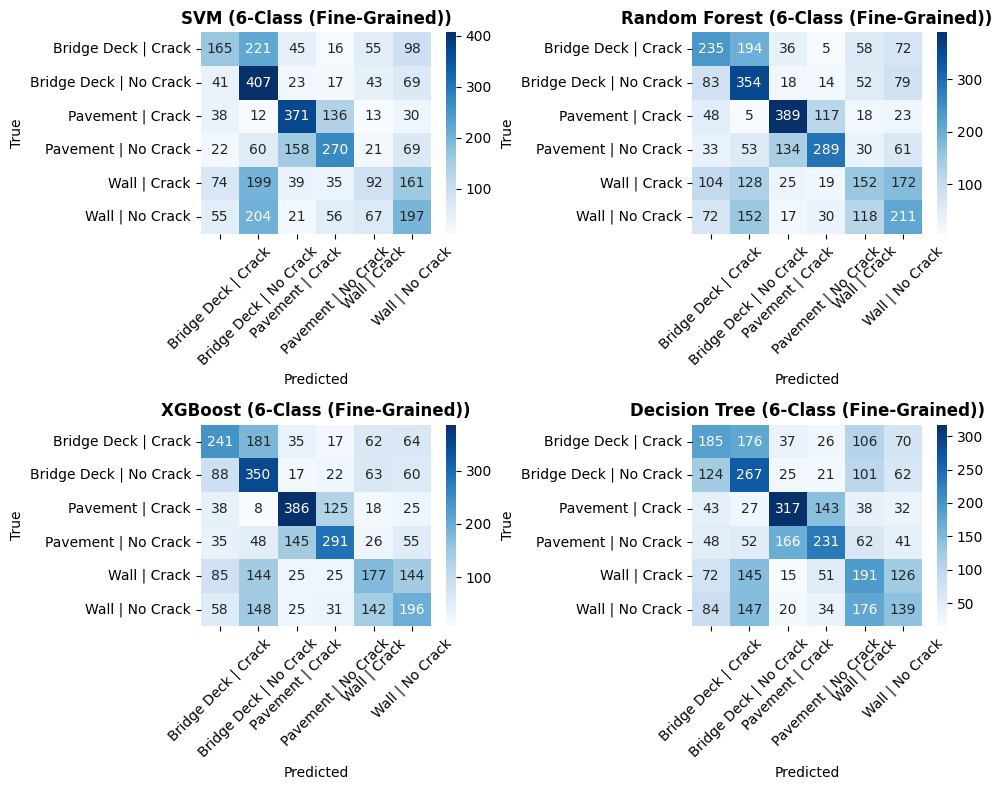


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [4]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30  # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Sample size per class for training

# =====================================================================
# 1. MSER TOP-20 REGION FEATURE EXTRACTION
# =====================================================================
def extract_cell_features(img_patch, max_regions=20):
    """
    Extracts top-20 MSER (Maximally Stable Extremal Regions) and converts them 
    into a fixed 60-dimensional vector: [x1, y1, area1, ..., x20, y20, area20]
    """
    if img_patch is None or img_patch.size == 0:
        return np.zeros(max_regions * 3, dtype=np.float32)

    # Pre-processing: Smooth surface noise while preserving crack boundaries
    gray_prep = cv2.bilateralFilter(img_patch, d=7, sigmaColor=50, sigmaSpace=50)

    # Initialize MSER detector
    mser = cv2.MSER_create(delta=2, min_area=8, max_area=5000)
    regions, _ = mser.detectRegions(gray_prep)

    vector = []
    if regions:
        # Sort regions by size (number of pixels) descending to prioritize prominent features
        regions = sorted(regions, key=lambda p: len(p), reverse=True)[:max_regions]

        for p in regions:
            # Compute moments to extract centroid (x, y) and area of the region
            M = cv2.moments(p)
            if M["m00"] != 0:
                cx = float(M["m10"] / M["m00"])
                cy = float(M["m01"] / M["m00"])
            else:
                cx, cy = 0.0, 0.0
            
            area = float(len(p)) # Area as region stability metric
            vector.extend([cx, cy, area])

    # Force exact target vector length = 60 (20 regions * 3 features)
    target_len = max_regions * 3
    if len(vector) < target_len:
        vector.extend([0.0] * (target_len - len(vector)))  # Zero-padding
    else:
        vector = vector[:target_len]                       # Truncate to top 20

    return np.array(vector, dtype=np.float32)


def extract_spatial_gradient_features(img_path, grid_size=(2, 2)):
    """
    Extracts global MSER features + 2x2 grid local MSER features.
    Total Dimensions = 60 (Global) + 4 * 60 (Grid Cells) = 300 Dimensions
    """
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None

    # Global Image Features (60-D)
    global_feats = extract_cell_features(img)

    # Spatial Grid Features (4 x 60-D = 240-D)
    h, w = img.shape
    rh, rw = h // grid_size[0], w // grid_size[1]
    
    grid_feats = []
    for r in range(grid_size[0]):
        for c in range(grid_size[1]):
            cell = img[r*rh:(r+1)*rh, c*rw:(c+1)*rw]
            grid_feats.append(extract_cell_features(cell))

    # Combine into single 300-D Feature Vector
    return np.hstack([global_feats] + grid_feats)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

for idx, (label_name, sample_path) in enumerate(class_samples.items()):
    if idx < 6:
        sample_img = cv2.imread(sample_path)
        sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(sample_img)
        axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

# Shuffle dataset paths to get random representative samples
np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 300-D MSER feature vectors for dataset images...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_spatial_gradient_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X, dtype=np.float32)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# =====================================================================
# 5. PIPELINE TRAINER WITH PER-CLASS BREAKDOWN & MACRO METRICS
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    # Configure XGBoost GPU Classifier
    xgb_clf = XGBClassifier(
        n_estimators=200, 
        learning_rate=0.08, 
        eval_metric='mlogloss', 
        random_state=42, 
        tree_method='hist',
        device='cuda'
    )

    # Models wrapped with Standard Scalers inside Pipelines
    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)),
        "XGBoost": make_pipeline(StandardScaler(), xgb_clf),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        # Fallback to CPU execution if GPU device isn't configured in environment
        try:
            model.fit(X_train, y_train)
        except Exception:
            if name == "XGBoost":
                model.named_steps['xgbclassifier'].set_params(device='cpu')
                model.fit(X_train, y_train)

        preds = model.predict(X_test)
        
        acc = accuracy_score(y_test, preds)
        
        # Macro averaging across all classes
        macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
            y_test, preds, average='macro', zero_division=0
        )
        macro_sens = macro_r  # Sensitivity = Recall

        # Per-class metrics
        per_p, per_r, per_f1, _ = precision_recall_fscore_support(
            y_test, preds, average=None, zero_division=0
        )
        
        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, "precision": macro_p, "recall": macro_r, 
            "sensitivity": macro_sens, "f1": macro_f1, "cm": cm
        }

        # Print formatted output matching target format
        print(f"\n---> {name} [{task_name}]")
        print(f" • Overall Accuracy   : {acc * 100:.2f}%")
        print(f" • Macro Precision    : {macro_p:.4f}")
        print(f" • Macro Sensitivity  : {macro_sens:.4f}  (Sensitivity = Recall)")
        print(f" • Macro F1-Score     : {macro_f1:.4f}\n")
        print("   --- Per-Class Performance Breakdown ---")
        for cls_idx, cls_name in enumerate(le.classes_):
            p_val = per_p[cls_idx]
            r_val = per_r[cls_idx]
            f_val = per_f1[cls_idx]
            print(f"   - {cls_name:<20} | Precision: {p_val:.4f} | Sensitivity/Recall: {r_val:.4f} | F1: {f_val:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_spatial_gradient_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            detected_surface, detected_condition = pred_label.split(" | ")

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()

spatial surf (With image grid)

🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


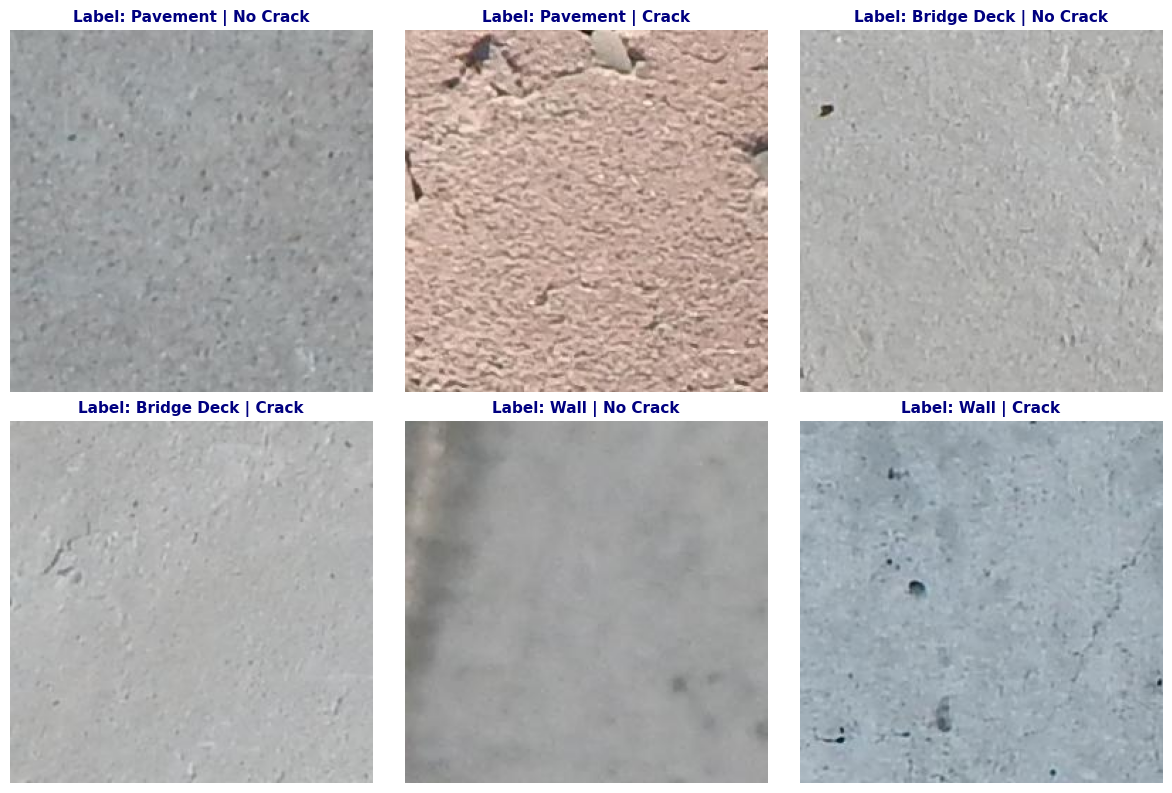


⚙️ Extracting 6400-D Spatial SURF feature vectors for dataset images...


100%|██████████| 56092/56092 [06:54<00:00, 135.41it/s] 



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Overall Accuracy   : 63.47%
 • Macro Precision    : 0.6384
 • Macro Sensitivity  : 0.6347  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6323

    --- Per-Class Performance Breakdown ---
    - Crack                | Precision: 0.6611 | Sensitivity/Recall: 0.5528 | F1: 0.6021
    - No Crack             | Precision: 0.6158 | Sensitivity/Recall: 0.7167 | F1: 0.6624

---> Random Forest [2-Class (Condition)]
 • Overall Accuracy   : 60.39%
 • Macro Precision    : 0.6050
 • Macro Sensitivity  : 0.6039  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6029

    --- Per-Class Performance Breakdown ---
    - Crack                | Precision: 0.6

/usr/local/lib/python3.12/dist-packages/xgboost/core.py:751: UserWarning: [14:46:27] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



---> XGBoost [2-Class (Condition)]
 • Overall Accuracy   : 63.42%
 • Macro Precision    : 0.6380
 • Macro Sensitivity  : 0.6342  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6316

    --- Per-Class Performance Breakdown ---
    - Crack                | Precision: 0.6609 | Sensitivity/Recall: 0.5511 | F1: 0.6010
    - No Crack             | Precision: 0.6151 | Sensitivity/Recall: 0.7172 | F1: 0.6622

---> Decision Tree [2-Class (Condition)]
 • Overall Accuracy   : 56.03%
 • Macro Precision    : 0.5649
 • Macro Sensitivity  : 0.5603  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5523

    --- Per-Class Performance Breakdown ---
    - Crack                | Precision: 0.5823 | Sensitivity/Recall: 0.4267 | F1: 0.4925
    - No Crack             | Precision: 0.5476 | Sensitivity/Recall: 0.6939 | F1: 0.6121


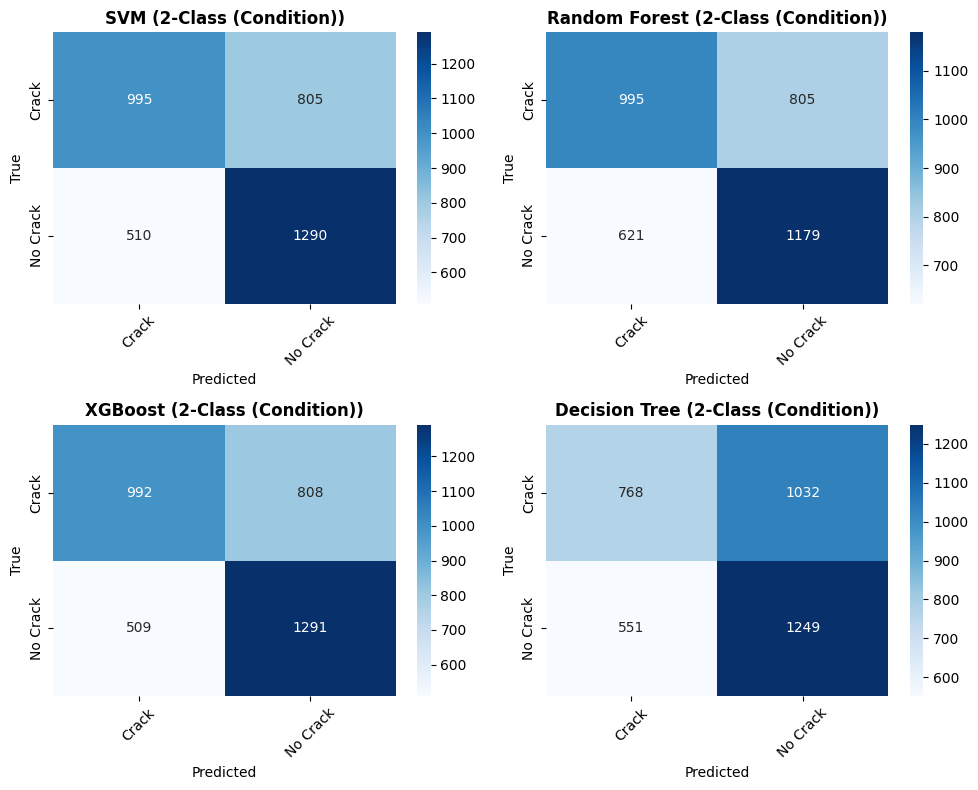


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Overall Accuracy   : 82.03%
 • Macro Precision    : 0.8243
 • Macro Sensitivity  : 0.8203  (Sensitivity = Recall)
 • Macro F1-Score     : 0.8202

    --- Per-Class Performance Breakdown ---
    - Bridge Deck          | Precision: 0.7507 | Sensitivity/Recall: 0.8533 | F1: 0.7988
    - Pavement             | Precision: 0.8942 | Sensitivity/Recall: 0.8733 | F1: 0.8836
    - Wall                 | Precision: 0.8280 | Sensitivity/Recall: 0.7342 | F1: 0.7783

---> Random Forest [3-Class (Surface Structure)]
 • Overall Accuracy   : 77.75%
 • Macro Precision    : 0.7824
 • Macro Sensitivity  : 0.7775  (Sensitivity = Recall)
 • Macro F1-Score     : 0.7785

    --- Per-Class Performance Breakdown ---
    - Bridge Deck          | Precision: 0.7223 | Sensitivity/Recall: 0.8083 | F1: 0.7629
    - Pavement             | Precision: 0.8925 | Sensitivity/Recall: 0.8167 | F1: 0.8529
    

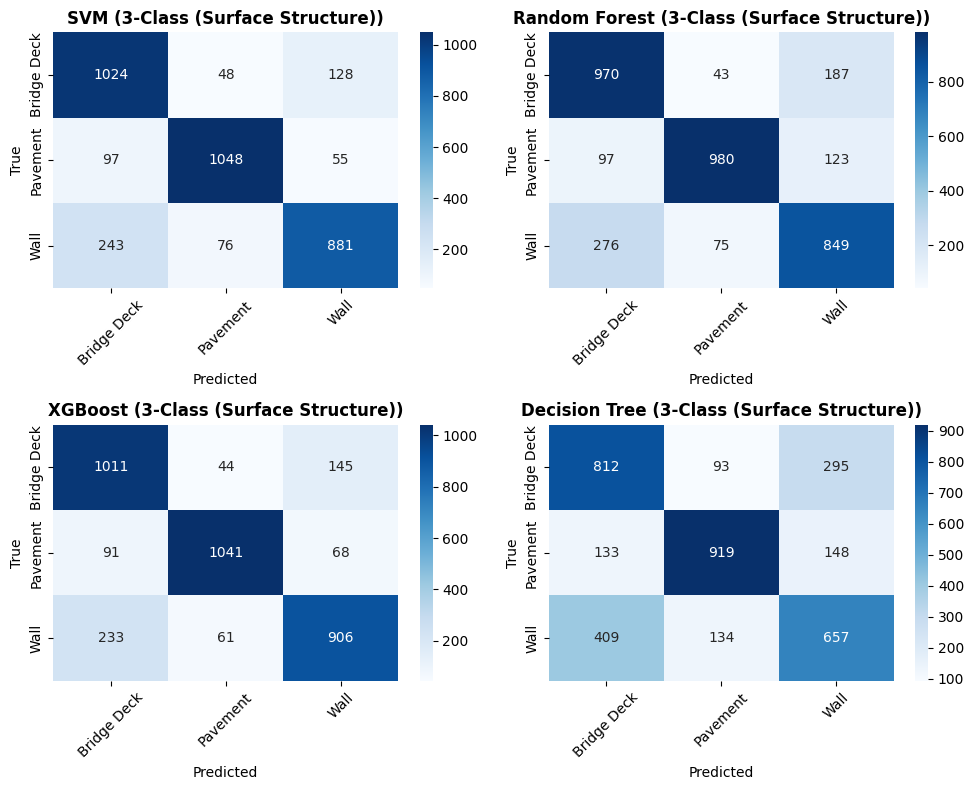


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Overall Accuracy   : 51.14%
 • Macro Precision    : 0.5166
 • Macro Sensitivity  : 0.5114  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5073

    --- Per-Class Performance Breakdown ---
    - Bridge Deck | Crack  | Precision: 0.5476 | Sensitivity/Recall: 0.4217 | F1: 0.4765
    - Bridge Deck | No Crack | Precision: 0.4553 | Sensitivity/Recall: 0.6967 | F1: 0.5507
    - Pavement | Crack     | Precision: 0.5570 | Sensitivity/Recall: 0.5783 | F1: 0.5675
    - Pavement | No Crack  | Precision: 0.5292 | Sensitivity/Recall: 0.4983 | F1: 0.5133
    - Wall | Crack         | Precision: 0.4707 | Sensitivity/Recall: 0.3750 | F1: 0.4174
    - Wall | No Crack      | Precision: 0.5397 | Sensitivity/Recall: 0.4983 | F1: 0.5182

---> Random Forest [6-Class (Fine-Grained)]
 • Overall Accuracy   : 47.61%
 • Macro Precision    : 0.4823
 • Macro Sensitivity  : 0.4761  (Sensitivity = Recall)
 • M

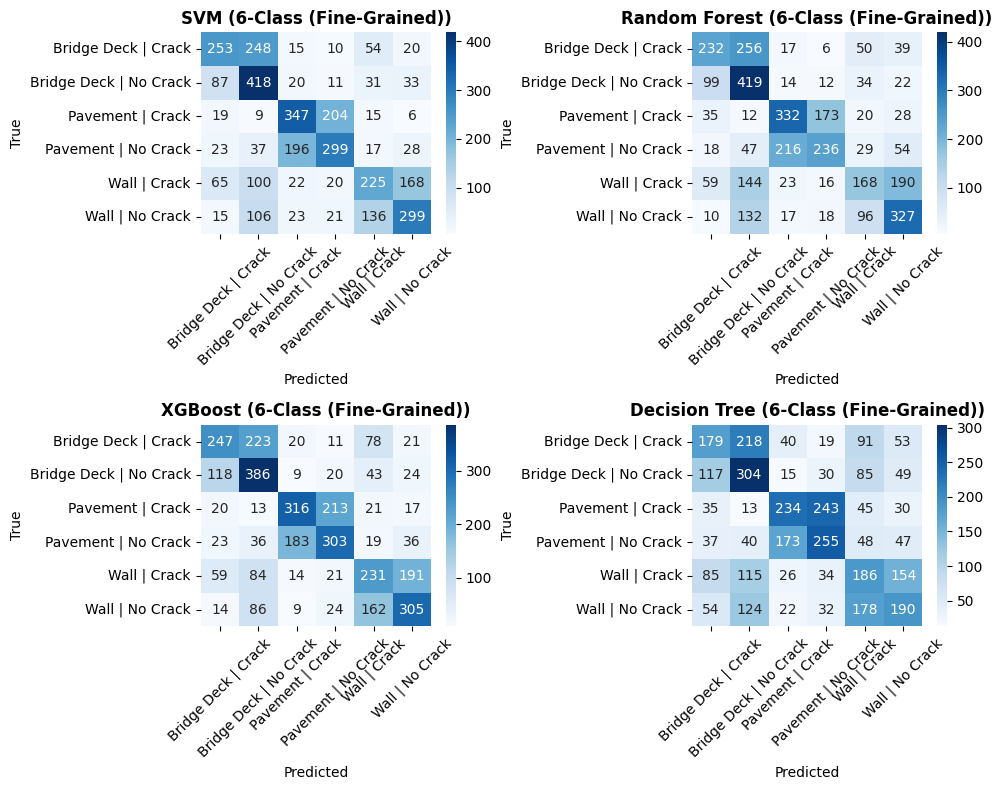


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30        # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000 # Sample size per class for training
MAX_KEYPOINTS = 20      # Top-20 SURF keypoints per cell/patch
DESCRIPTOR_DIM = 64     # Standard SURF descriptor dimension

# =====================================================================
# 1. SURF TOP-20 KEYPOINT FEATURE EXTRACTION
# =====================================================================
def extract_cell_features(img_patch, max_keypoints=MAX_KEYPOINTS):
    """
    Extracts top-20 SURF keypoint descriptors and flattens them into a fixed 
    1280-dimensional vector (20 keypoints * 64 descriptor values).
    
    Includes native SURF extraction with automatic fallback (FAST/SIFT/ORB)
    matching your provided feature extraction suite snippet.
    """
    target_dim = max_keypoints * DESCRIPTOR_DIM
    if img_patch is None or img_patch.size == 0:
        return np.zeros(target_dim, dtype=np.float32)

    # Pre-processing: Smooth surface noise while preserving crack boundaries
    gray_prep = cv2.bilateralFilter(img_patch, d=7, sigmaColor=50, sigmaSpace=50)

    descriptors = None
    
    # --- 5. SURF / Hessian-Fast Keypoint Extraction (from provided snippet) ---
    try:
        surf = cv2.xfeatures2d.SURF_create(hessianThreshold=350)
        _, descriptors = surf.detectAndCompute(gray_prep, None)
    except Exception:
        try:
            # Fallback 1: FastFeatureDetector + SIFT Descriptor
            fast = cv2.FastFeatureDetector_create(threshold=15)
            kp = fast.detect(gray_prep, None)
            sift = cv2.SIFT_create()
            kp, descriptors = sift.compute(gray_prep, kp)
            if descriptors is not None and descriptors.shape[1] == 128:
                descriptors = descriptors[:, :DESCRIPTOR_DIM]  # Truncate 128-D SIFT to 64-D
        except Exception:
            # Fallback 2: ORB Detector
            orb = cv2.ORB_create(nfeatures=max_keypoints)
            kp, descriptors = orb.detectAndCompute(gray_prep, None)
            if descriptors is not None:
                descriptors = np.pad(descriptors, ((0, 0), (0, 32)), mode='constant')

    if descriptors is None or len(descriptors) == 0:
        return np.zeros(target_dim, dtype=np.float32)

    # Sort/select top 20 descriptors
    descriptors = descriptors[:max_keypoints]
    flat_vector = descriptors.flatten()

    # Enforce exact target vector length (1280-D) via padding or truncation
    if len(flat_vector) < target_dim:
        flat_vector = np.pad(flat_vector, (0, target_dim - len(flat_vector)), mode='constant')
    else:
        flat_vector = flat_vector[:target_dim]

    return flat_vector.astype(np.float32)


def extract_spatial_gradient_features(img_path, grid_size=(2, 2)):
    """
    Extracts global SURF features + 2x2 grid local SURF features.
    Total Dimensions = 1280 (Global) + 4 * 1280 (Grid Cells) = 6400 Dimensions
    """
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None

    # Global Image Features (1280-D)
    global_feats = extract_cell_features(img)

    # Spatial Grid Features (4 x 1280-D = 5120-D)
    h, w = img.shape
    rh, rw = h // grid_size[0], w // grid_size[1]
    
    grid_feats = []
    for r in range(grid_size[0]):
        for c in range(grid_size[1]):
            cell = img[r*rh:(r+1)*rh, c*rw:(c+1)*rw]
            grid_feats.append(extract_cell_features(cell))

    # Combine into single 6400-D Feature Vector
    return np.hstack([global_feats] + grid_feats)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

for idx, (label_name, sample_path) in enumerate(class_samples.items()):
    if idx < 6:
        sample_img = cv2.imread(sample_path)
        sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(sample_img)
        axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

# Shuffle dataset paths to get random representative samples
np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 6400-D Spatial SURF feature vectors for dataset images...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_spatial_gradient_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X, dtype=np.float32)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# =====================================================================
# 5. PIPELINE TRAINER WITH PER-CLASS BREAKDOWN & MACRO METRICS
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    # Configure XGBoost GPU Classifier
    xgb_clf = XGBClassifier(
        n_estimators=200, 
        learning_rate=0.08, 
        eval_metric='mlogloss', 
        random_state=42, 
        tree_method='hist',
        device='cuda'
    )

    # Models wrapped with Standard Scalers inside Pipelines
    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)),
        "XGBoost": make_pipeline(StandardScaler(), xgb_clf),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        # Fallback to CPU execution if GPU device isn't configured in environment
        try:
            model.fit(X_train, y_train)
        except Exception:
            if name == "XGBoost":
                model.named_steps['xgbclassifier'].set_params(device='cpu')
                model.fit(X_train, y_train)

        preds = model.predict(X_test)
        
        acc = accuracy_score(y_test, preds)
        
        # Macro averaging across all classes
        macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
            y_test, preds, average='macro', zero_division=0
        )
        macro_sens = macro_r  # Sensitivity = Recall

        # Per-class metrics
        per_p, per_r, per_f1, _ = precision_recall_fscore_support(
            y_test, preds, average=None, zero_division=0
        )
        
        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, "precision": macro_p, "recall": macro_r, 
            "sensitivity": macro_sens, "f1": macro_f1, "cm": cm
        }

        # Print formatted output matching target format
        print(f"\n---> {name} [{task_name}]")
        print(f" • Overall Accuracy   : {acc * 100:.2f}%")
        print(f" • Macro Precision    : {macro_p:.4f}")
        print(f" • Macro Sensitivity  : {macro_sens:.4f}  (Sensitivity = Recall)")
        print(f" • Macro F1-Score     : {macro_f1:.4f}\n")
        print("    --- Per-Class Performance Breakdown ---")
        for cls_idx, cls_name in enumerate(le.classes_):
            p_val = per_p[cls_idx]
            r_val = per_r[cls_idx]
            f_val = per_f1[cls_idx]
            print(f"    - {cls_name:<20} | Precision: {p_val:.4f} | Sensitivity/Recall: {r_val:.4f} | F1: {f_val:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_spatial_gradient_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            detected_surface, detected_condition = pred_label.split(" | ")

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()

BRISK with image Grid

⚡ RAPIDS cuML & CuPy detected! Utilizing GPU acceleration for ML models.
🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


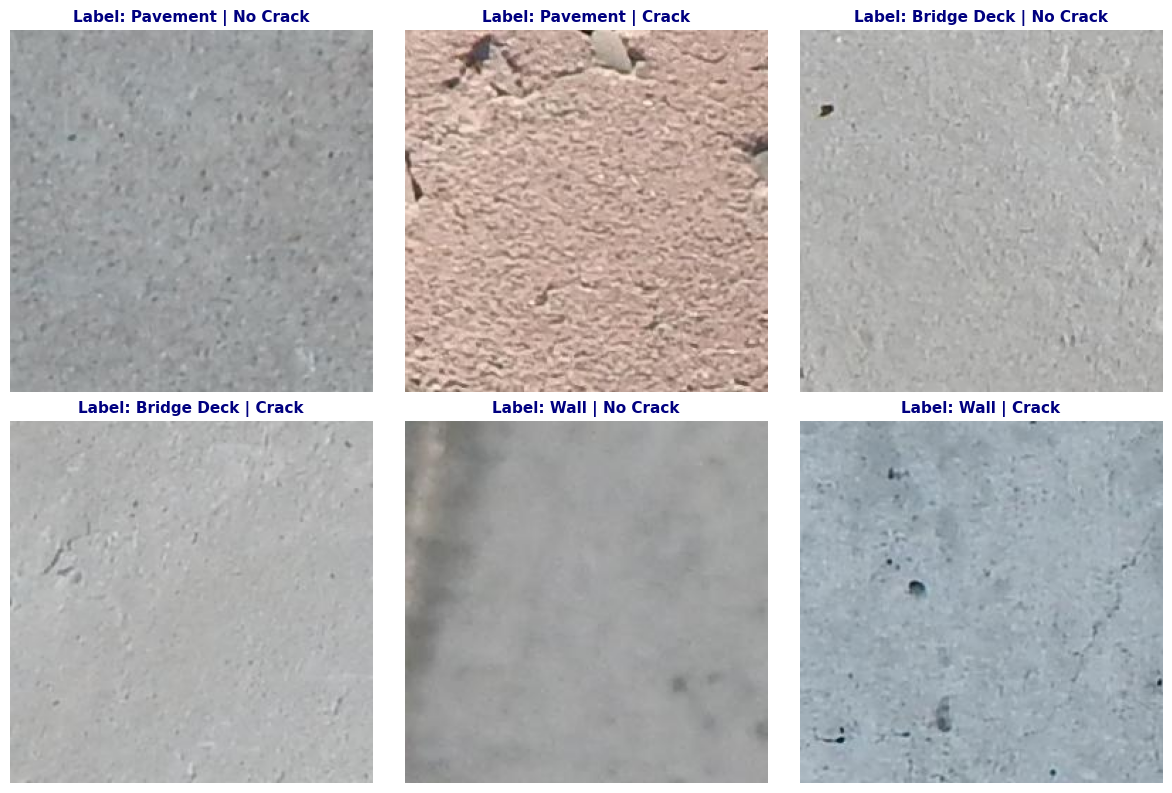


⚙️ Extracting 1280-D Patch-based BRISK feature vectors (2x2 Grid) for dataset images...


100%|██████████| 56092/56092 [11:26<00:00, 81.65it/s] 



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM (GPU) [2-Class (Condition)]
 • Overall Accuracy   : 55.78%
 • Macro Precision    : 0.5579
 • Macro Sensitivity  : 0.5578  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5575

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.5552 | Sensitivity/Recall: 0.5811 | F1: 0.5679
   - No Crack             | Precision: 0.5606 | Sensitivity/Recall: 0.5344 | F1: 0.5472

---> Random Forest (GPU) [2-Class (Condition)]
 • Overall Accuracy   : 56.03%
 • Macro Precision    : 0.5611
 • Macro Sensitivity  : 0.5603  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5588

    --- Per-Class Performance Breakdown ---
   - Crack                | Preci

/usr/local/lib/python3.12/dist-packages/xgboost/core.py:751: UserWarning: [19:47:49] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



---> XGBoost (GPU) [2-Class (Condition)]
 • Overall Accuracy   : 57.69%
 • Macro Precision    : 0.5803
 • Macro Sensitivity  : 0.5769  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5725

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.5967 | Sensitivity/Recall: 0.4750 | F1: 0.5289
   - No Crack             | Precision: 0.5639 | Sensitivity/Recall: 0.6789 | F1: 0.6161

---> Decision Tree [2-Class (Condition)]
 • Overall Accuracy   : 53.36%
 • Macro Precision    : 0.5384
 • Macro Sensitivity  : 0.5336  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5186

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.5519 | Sensitivity/Recall: 0.3572 | F1: 0.4337
   - No Crack             | Precision: 0.5248 | Sensitivity/Recall: 0.7100 | F1: 0.6035


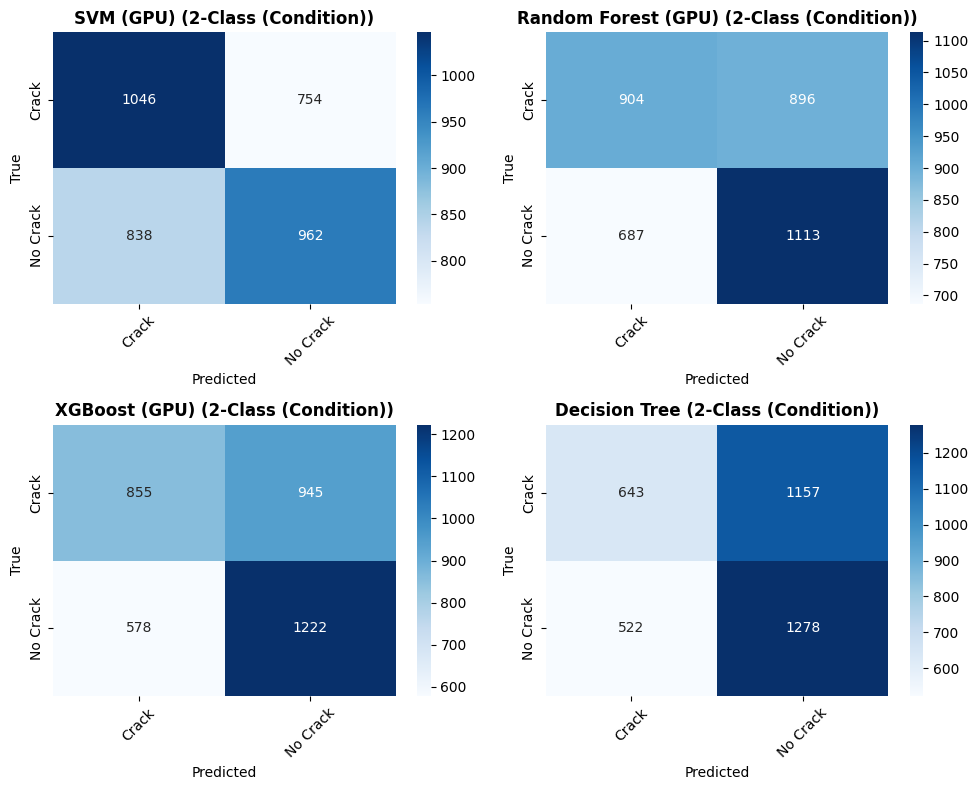


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM (GPU) [3-Class (Surface Structure)]
 • Overall Accuracy   : 63.72%
 • Macro Precision    : 0.6559
 • Macro Sensitivity  : 0.6372  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6366

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5412 | Sensitivity/Recall: 0.7450 | F1: 0.6269
   - Pavement             | Precision: 0.8368 | Sensitivity/Recall: 0.7092 | F1: 0.7677
   - Wall                 | Precision: 0.5897 | Sensitivity/Recall: 0.4575 | F1: 0.5153

---> Random Forest (GPU) [3-Class (Surface Structure)]
 • Overall Accuracy   : 61.86%
 • Macro Precision    : 0.6297
 • Macro Sensitivity  : 0.6186  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6188

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5503 | Sensitivity/Recall: 0.7025 | F1: 0.6171
   - Pavement             | Precision: 0.8103 | Sensitivity/Recall: 0.6975 | F1: 0.74

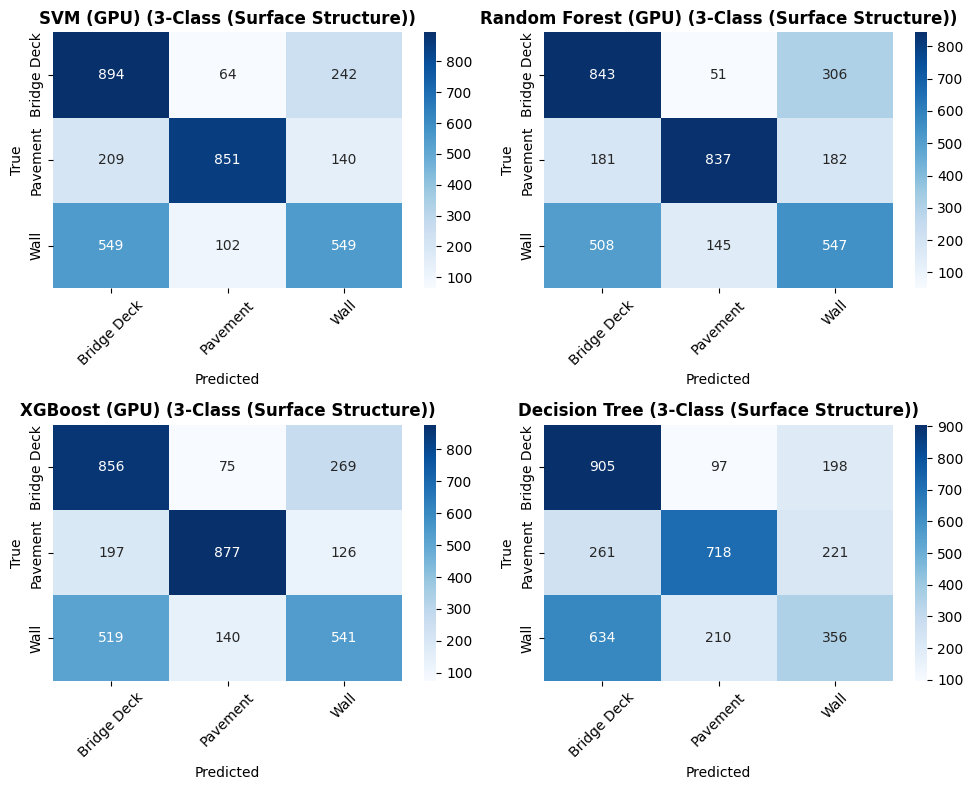


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM (GPU) [6-Class (Fine-Grained)]
 • Overall Accuracy   : 36.81%
 • Macro Precision    : 0.3750
 • Macro Sensitivity  : 0.3681  (Sensitivity = Recall)
 • Macro F1-Score     : 0.3532

    --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.2931 | Sensitivity/Recall: 0.1900 | F1: 0.2305
   - Bridge Deck | No Crack | Precision: 0.3126 | Sensitivity/Recall: 0.6950 | F1: 0.4312
   - Pavement | Crack     | Precision: 0.5078 | Sensitivity/Recall: 0.4900 | F1: 0.4987
   - Pavement | No Crack  | Precision: 0.4807 | Sensitivity/Recall: 0.3950 | F1: 0.4337
   - Wall | Crack         | Precision: 0.3050 | Sensitivity/Recall: 0.2150 | F1: 0.2522
   - Wall | No Crack      | Precision: 0.3508 | Sensitivity/Recall: 0.2233 | F1: 0.2729

---> Random Forest (GPU) [6-Class (Fine-Grained)]
 • Overall Accuracy   : 35.94%
 • Macro Precision    : 0.3648
 • Macro Sensitivity  : 0.3594  (Sensitivity = Recall

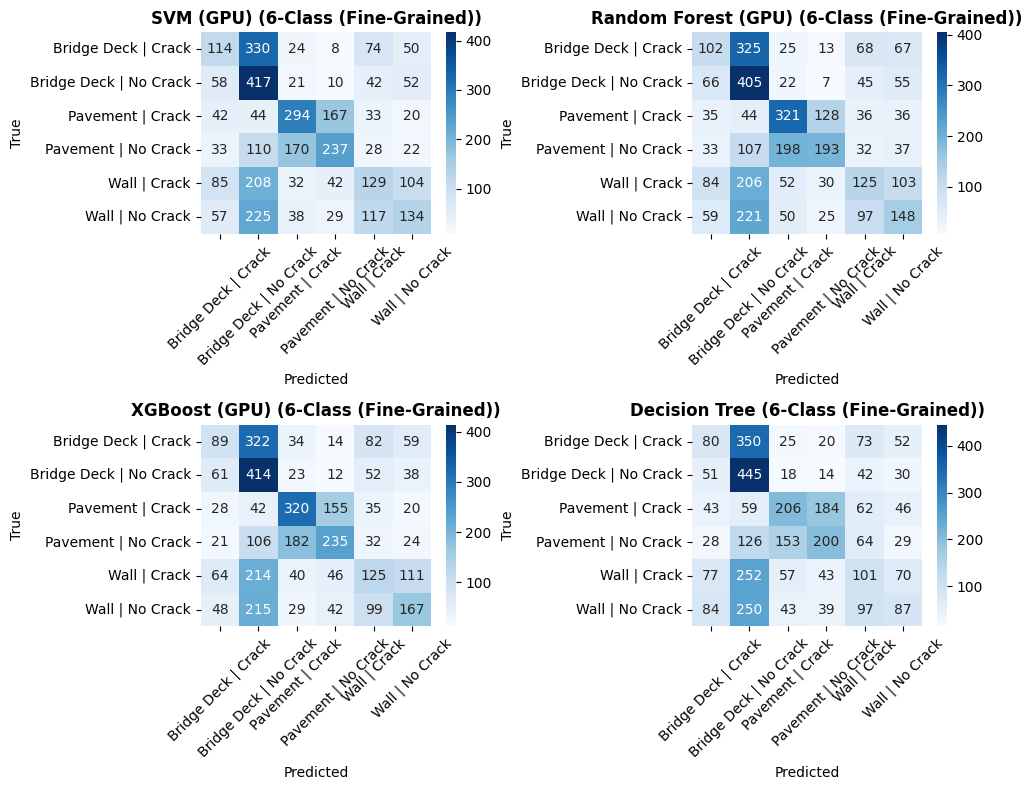


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix
)

# --- GPU Acceleration Imports (RAPIDS cuML & CuPy) ---
try:
    import cupy as cp
    import cuml
    from cuml.svm import SVC as cumlSVC
    from cuml.ensemble import RandomForestClassifier as cumlRandomForest
    from cuml.preprocessing import StandardScaler as cumlStandardScaler
    HAS_CUML = True
    print("⚡ RAPIDS cuML & CuPy detected! Utilizing GPU acceleration for ML models.")
except ImportError:
    HAS_CUML = False
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVC
    from sklearn.ensemble import RandomForestClassifier
    print("⚠️ cuML/CuPy not found. Defaulting to Scikit-Learn CPU models with GPU XGBoost.")

from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30          # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Sample size per class for training
GRID_ROWS = 2             # 2x2 Spatial Grid (4 Patches total)
GRID_COLS = 2
KPS_PER_PATCH = 5         # Top 5 keypoints per patch (4 patches * 5 = 20 total keypoints)
DESCRIPTOR_DIM = 64        # BRISK descriptor size (64 bytes)
TARGET_DIM = GRID_ROWS * GRID_COLS * KPS_PER_PATCH * DESCRIPTOR_DIM  # Fixed 1280-D Feature Vector

# =====================================================================
# 1. SPATIAL PATCH-BASED BRISK FEATURE EXTRACTION (2x2 GRID)
# =====================================================================
def extract_brisk_patch_features(img_path_or_array):
    """
    Splits the image into a 2x2 grid (4 spatial patches).
    Extracts the top 5 keypoints per patch based on response strength.
    Zero-pads missing descriptors per patch to guarantee equal spatial representation.
    Returns: Fixed 1280-D vector (4 patches * 5 keypoints * 64 dimensions = 20 keypoints total).
    """
    if isinstance(img_path_or_array, str):
        img = cv2.imread(img_path_or_array, cv2.IMREAD_GRAYSCALE)
    else:
        img = img_path_or_array

    if img is None or img.size == 0:
        return np.zeros(TARGET_DIM, dtype=np.float32)

    # Noise filtering while preserving sharp crack boundary contrast
    prep_img = cv2.bilateralFilter(img, d=7, sigmaColor=50, sigmaSpace=50)
    h, w = prep_img.shape

    # Instantiate BRISK with robust fallback
    try:
        try:
            brisk = cv2.BRISK_create(thresh=30, octaves=3)
        except AttributeError:
            brisk = cv2.BRISK.create(thresh=30, octaves=3)
    except Exception:
        brisk = cv2.ORB_create(nfeatures=50)

    patch_vectors = []
    patch_h, patch_w = h // GRID_ROWS, w // GRID_COLS

    # Iterate through 2x2 grid quadrants
    for r in range(GRID_ROWS):
        for c in range(GRID_COLS):
            y_start, y_end = r * patch_h, (r + 1) * patch_h if r < GRID_ROWS - 1 else h
            x_start, x_end = c * patch_w, (c + 1) * patch_w if c < GRID_COLS - 1 else w

            patch = prep_img[y_start:y_end, x_start:x_end]
            keypoints, descriptors = brisk.detectAndCompute(patch, None)

            patch_target_len = KPS_PER_PATCH * DESCRIPTOR_DIM

            if descriptors is None or len(descriptors) == 0:
                patch_vec = np.zeros(patch_target_len, dtype=np.float32)
            else:
                # Sort keypoints inside this local patch by response strength
                if len(keypoints) == len(descriptors):
                    sorted_pairs = sorted(zip(keypoints, descriptors), key=lambda x: x[0].response, reverse=True)
                    descriptors = np.array([desc for _, desc in sorted_pairs])

                # Retain Top 5 keypoints within this quadrant
                descriptors = descriptors[:KPS_PER_PATCH]
                patch_vec = descriptors.flatten()

                # Pad or truncate to 320 dimensions per patch (5 * 64)
                if len(patch_vec) < patch_target_len:
                    patch_vec = np.pad(patch_vec, (0, patch_target_len - len(patch_vec)), mode='constant')
                else:
                    patch_vec = patch_vec[:patch_target_len]

            patch_vectors.append(patch_vec)

    # Stacks 4 quadrant vectors into a single 1280-D vector
    final_vector = np.concatenate(patch_vectors)
    return final_vector.astype(np.float32)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images in Kaggle input
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

if class_samples:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes = axes.ravel()

    for idx, (label_name, sample_path) in enumerate(class_samples.items()):
        if idx < 6:
            sample_img = cv2.imread(sample_path)
            sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(sample_img)
            axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
            axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 1280-D Patch-based BRISK feature vectors (2x2 Grid) for dataset images...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_brisk_patch_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X, dtype=np.float32)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

if len(X) == 0:
    print("\n[!] No matching images found in /kaggle/input. Generating synthetic data for pipeline validation...")
    X = np.random.randn(600, TARGET_DIM).astype(np.float32)
    y_2class = np.random.choice(["Crack", "No Crack"], size=600)
    y_3class = np.random.choice(["Bridge Deck", "Pavement", "Wall"], size=600)
    y_6class = np.array([f"{s} | {c}" for s, c in zip(y_3class, y_2class)])

# =====================================================================
# 5. PIPELINE TRAINER WITH GPU-ACCELERATED MODELS
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    # Scale Data using GPU scaler if available
    if HAS_CUML:
        scaler = cumlStandardScaler()
        X_train_scaled = scaler.fit_transform(cp.array(X_train))
        X_test_scaled = scaler.transform(cp.array(X_test))
    else:
        from sklearn.preprocessing import StandardScaler
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

    # XGBoost GPU Classifier
    xgb_clf = XGBClassifier(
        n_estimators=200, 
        learning_rate=0.08, 
        eval_metric='mlogloss', 
        random_state=42, 
        tree_method='hist',
        device='cuda'
    )

    # Configure Models (cuML GPU Models or CPU Fallbacks)
    if HAS_CUML:
        models = {
            "SVM (GPU)": cumlSVC(kernel='rbf', C=5.0, probability=True),
            "Random Forest (GPU)": cumlRandomForest(n_estimators=200, max_depth=20, random_state=42),
            "XGBoost (GPU)": xgb_clf,
            "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42)
        }
    else:
        from sklearn.svm import SVC
        from sklearn.ensemble import RandomForestClassifier
        models = {
            "SVM": SVC(kernel='rbf', C=5.0, probability=True, random_state=42),
            "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1),
            "XGBoost (GPU)": xgb_clf,
            "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42)
        }

    trained = {}
    metrics = {}

    for name, model in models.items():
        # Fit models on GPU or CPU arrays
        if HAS_CUML and "GPU" in name and "XGBoost" not in name:
            model.fit(X_train_scaled, cp.array(y_train))
            preds_gpu = model.predict(X_test_scaled)
            preds = cp.asnumpy(preds_gpu) if hasattr(preds_gpu, 'get') or isinstance(preds_gpu, cp.ndarray) else preds_gpu
        else:
            X_tr = cp.asnumpy(X_train_scaled) if HAS_CUML and hasattr(X_train_scaled, 'get') else X_train_scaled
            X_te = cp.asnumpy(X_test_scaled) if HAS_CUML and hasattr(X_test_scaled, 'get') else X_test_scaled
            model.fit(X_tr, y_train)
            preds = model.predict(X_te)

        acc = accuracy_score(y_test, preds)
        macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
            y_test, preds, average='macro', zero_division=0
        )
        macro_sens = macro_r
        per_p, per_r, per_f1, _ = precision_recall_fscore_support(
            y_test, preds, average=None, zero_division=0
        )
        cm = confusion_matrix(y_test, preds)

        trained[name] = (model, scaler)
        metrics[name] = {
            "accuracy": acc, "precision": macro_p, "recall": macro_r, 
            "sensitivity": macro_sens, "f1": macro_f1, "cm": cm
        }

        print(f"\n---> {name} [{task_name}]")
        print(f" • Overall Accuracy   : {acc * 100:.2f}%")
        print(f" • Macro Precision    : {macro_p:.4f}")
        print(f" • Macro Sensitivity  : {macro_sens:.4f}  (Sensitivity = Recall)")
        print(f" • Macro F1-Score     : {macro_f1:.4f}\n")
        print("    --- Per-Class Performance Breakdown ---")
        for cls_idx, cls_name in enumerate(le.classes_):
            p_val = per_p[cls_idx]
            r_val = per_r[cls_idx]
            f_val = per_f1[cls_idx]
            print(f"   - {cls_name:<20} | Precision: {p_val:.4f} | Sensitivity/Recall: {r_val:.4f} | F1: {f_val:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_brisk_patch_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract BRISK features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            xgb_key = [k for k in models_6c.keys() if "XGBoost" in k][0]
            primary_model, primary_scaler = models_6c[xgb_key]
            
            feats_scaled = primary_scaler.transform([feats])
            if HAS_CUML and hasattr(feats_scaled, 'get'):
                feats_scaled = cp.asnumpy(feats_scaled)

            pred_code = primary_model.predict(feats_scaled)[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            if " | " in pred_label:
                detected_surface, detected_condition = pred_label.split(" | ")
            else:
                detected_surface, detected_condition = pred_label, "Unknown"

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                m2, s2 = models_2c[m_name]
                m3, s3 = models_3c[m_name]
                m6, s6 = models_6c[m_name]

                f2 = s2.transform([feats])
                f3 = s3.transform([feats])
                f6 = s6.transform([feats])

                if HAS_CUML and "GPU" in m_name and "XGBoost" not in m_name:
                    p2 = cp.asnumpy(m2.predict(cp.array(f2)))[0]
                    p3 = cp.asnumpy(m3.predict(cp.array(f3)))[0]
                    p6 = cp.asnumpy(m6.predict(cp.array(f6)))[0]
                else:
                    p2 = m2.predict(cp.asnumpy(f2) if HAS_CUML and hasattr(f2, 'get') else f2)[0]
                    p3 = m3.predict(cp.asnumpy(f3) if HAS_CUML and hasattr(f3, 'get') else f3)[0]
                    p6 = m6.predict(cp.asnumpy(f6) if HAS_CUML and hasattr(f6, 'get') else f6)[0]

                p_2c = le_2c.inverse_transform([p2])[0]
                p_3c = le_3c.inverse_transform([p3])[0]
                p_6c = le_6c.inverse_transform([p6])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()